# Proyecto Final Integrador: Detección Espacio-Temporal de Violencia Urbana y Evaluación de Transferencia de Dominio hacia Videovigilancia en Lima Metropolitana
**Asignatura:** MIA-203 Redes Neuronales y Aprendizaje Profundo — Unidad de Posgrado FIIS, Universidad Nacional de Ingeniería (UNI)  
**Docente:** Dr. Aldo Camargo Fernández-Baca, Ph.D.  
**Equipo de Investigación:**
* Alvaro Alejandro Siesquén Abad
* Kiara Isumi Alvarez Barrionuevo
* Sergio Alonso Ortiz Pauca
* Alfonso Pérez Ramos

---

### Cumplimiento de los Requisitos Obligatorios de la Rúbrica (R1–R6)
1. **R1 (Fundamento en el curso):** Combinación de **CNN (ResNet-50 preentrenada en ImageNet)** como extractor espacial de características por fotograma + **Redes Recurrentes (Bi-LSTM / GRU / RNN Vanilla)** para modelar la secuencia dinámica del movimiento + **Mecanismo de Atención Temporal** + **Optimización con AdamW y Cosine Annealing**.
2. **R2 (Originalidad y Contexto Peruano):** Arquitectura híbrida espacio-temporal evaluada tanto en distribución (*In-Domain*: dataset *Real-Life Violence Situations - RLVS*) como fuera de dominio (*Out-of-Domain*: condiciones de cámaras de videovigilancia/serenazgo de Lima Metropolitana mediante degradación CCTV y clips reales locales).
3. **R3 (Línea Base / Baseline):** Comparación directa contra una **CNN 2D sin memoria temporal (ResNet-50 Frame-Averaging)** y contra una **RNN Vanilla**.
4. **R4 (Experimentación y Ablaciones):** Partición estricta a nivel de **videos completos (70% Train / 15% Val / 15% Test)** garantizando **cero fuga de datos (*Zero Data Leakage*)**. Incluye estudios de ablación sobre el módulo temporal y robustez ante degradación CCTV.
5. **R5 (Interpretabilidad / XAI):** Explicabilidad dual: **Espacial (Grad-CAM)** sobre `layer4` de ResNet-50 + **Temporal (Curva de pesos de atención $\alpha_t$)** identificando qué fotogramas exactos disparan la alerta de violencia.
6. **R6 (Costo Computacional y Responsabilidad Ética):** Registro automático de horas de GPU (NVIDIA T4) y memoria VRAM consumida, junto con el análisis de costos asimétricos (Falsos Positivos vs. Falsos Negativos) en centrales de serenazgo de Lima.

## Inicial: Configuración del Entorno, Semillas de Reproducibilidad y Hardware (R6)
Instalación de dependencias, fijación determinista de semillas (`seed = 42`) y verificación de la GPU asignada en Google Colab.

In [ ]:
# Instalación de librerías requeridas en Google Colab
!pip install -q kagglehub opencv-python-headless scikit-learn grad-cam matplotlib seaborn tqdm pyyaml pandas

import os
import time
import glob
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# 1. Fijamos semilla global
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# 2. Verificamos la de GPU y registro de hardware (R6)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"VRAM Total: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# Creamos estructura local de carpetas para resultados y pesos
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("data_lima_cctv/Violence", exist_ok=True)
os.makedirs("data_lima_cctv/NonViolence", exist_ok=True)
#Creamos carpeta de pruebas:
os.makedirs("Pruebas/Violencia", exist_ok=True)
os.makedirs("Pruebas/No_Violencia", exist_ok=True)

Dispositivo activo: cuda
GPU detectada: Tesla T4
VRAM Total: 14.56 GB


## Bloque 1: Descarga e Integración Multi-Dataset (RLVS, RWF-2000, UCF-Crime y Clips Lima) sin Fuga de Datos (R4)
Para enriquecer el espacio de representación y evaluar la transferencia de dominio, integramos de manera modular y trazable las fuentes recomendadas:
1. **RLVS (Real-Life Violence Situations):** 2,000 videos base (`mohamedmustafa/real-life-violence-situations-dataset`).
2. **RWF-2000 (Real-World Fight Dataset):** Videos cortos capturados exclusivamente por cámaras de vigilancia fija (CCTV).
3. **UCF-Crime (Subconjunto Peleas/Agresiones):** Cámaras de seguridad con perspectivas cenitales reales.
4. **Clips CCTV de Lima Metropolitana:** Subcarpeta local `data_lima_cctv/` para videos reales de serenazgo/CCTV vecinal.

> **Control Estricto de Fuga de Datos (*Zero Data Leakage*):** Cada fuente se etiqueta con su origen (`source`) y la partición `Train / Val / Test` se realiza a nivel de video. Los videos de CCTV de Lima se reservan para la prueba de generalización *Out-of-Domain*.

In [ ]:
import os
import glob
import shutil
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

# Asegurar que existan las carpetas de Pruebas
os.makedirs("Pruebas/Violencia", exist_ok=True)
os.makedirs("Pruebas/No_Violencia", exist_ok=True)

# 1. Dataset Base RLVS (2,000 videos)
rlvs_path = kagglehub.dataset_download("mohamedmustafa/real-life-violence-situations-dataset")
rlvs_v, rlvs_nv = [], []
for root, dirs, _ in os.walk(rlvs_path):
    if "Violence" in dirs and "NonViolence" in dirs:
        rlvs_v  = sorted(glob.glob(os.path.join(root, "Violence", "*.*")))
        rlvs_nv = sorted(glob.glob(os.path.join(root, "NonViolence", "*.*")))
        break

data_records = [
    *[{"video_path": p, "label": 1, "class_name": "Violence", "source": "RLVS"} for p in rlvs_v],
    *[{"video_path": p, "label": 0, "class_name": "NonViolence", "source": "RLVS"} for p in rlvs_nv]
]
print(f"1) RLVS cargado: {len(data_records)} videos.")

# 2. Agregamos Datasets Públicos Adicionales de Violencia en Video (Sin bloqueo 403)
extra_datasets = [
    "yassershrief/hockey-fight-vidoes",              # ~1,000 videos adicionales (Fi / NoFi)
    "naveenk903/movies-fight-detection-dataset",     # ~200 videos adicionales de peleas vs normal
]

for ds_slug in extra_datasets:
    try:
        ds_path = kagglehub.dataset_download(ds_slug)
        added = 0
        for root, _, files in os.walk(ds_path):
            for f in files:
                if f.lower().endswith(('.mp4', '.avi', '.mpg', '.mkv')):
                    full_p = os.path.join(root, f)
                    folder_low = os.path.basename(root).lower()
                    fname_low = f.lower()
                    if "nofi" in folder_low or "nofi" in fname_low or "non" in folder_low or fname_low.startswith("no"):
                        data_records.append({"video_path": full_p, "label": 0, "class_name": "NonViolence", "source": ds_slug.split("/")[1]})
                        added += 1
                    elif "fi" in folder_low or "fi" in fname_low or "ights" in folder_low:
                        data_records.append({"video_path": full_p, "label": 1, "class_name": "Violence", "source": ds_slug.split("/")[1]})
                        added += 1
        print(f"2) Dataset adicional [{ds_slug}] agregado: +{added} videos nuevos.")
    except Exception as e:
        print(f"No se pudo agregar {ds_slug}: {e}")

# 3. Ingesta de videos locales CCTV Lima Metropolitana (si existen en la carpeta)
lima_v_vids = sorted(glob.glob("data_lima_cctv/Violence/*.*"))
lima_nv_vids = sorted(glob.glob("data_lima_cctv/NonViolence/*.*"))
for p in lima_v_vids:
    data_records.append({"video_path": p, "label": 1, "class_name": "Violence", "source": "Lima_CCTV"})
for p in lima_nv_vids:
    data_records.append({"video_path": p, "label": 0, "class_name": "NonViolence", "source": "Lima_CCTV"})

df_master = pd.DataFrame(data_records)
print(f"\n=== TOTAL BRUTO ACUMULADO: {len(df_master)} VIDEOS ===")

# ==============================================================================
# 3.5 RESERVAR 12 VIDEOS PARA PRUEBAS PROPIAS (2 Violencia y 2 No_Violencia por fuente)
#     Se copian a Pruebas/ y se EXCLUYEN de df_master para que el modelo jamás los vea
# ==============================================================================
fuentes_objetivo = ["RLVS", "hockey-fight-vidoes", "movies-fight-detection-dataset"]
indices_reservados = []
registros_pruebas = []

for fuente in fuentes_objetivo:
    for label_val, carpeta_destino in [(1, "Pruebas/Violencia"), (0, "Pruebas/No_Violencia")]:
        sub_df = df_master[(df_master["source"] == fuente) & (df_master["label"] == label_val)]
        # Seleccionamos 2 videos de forma determinista con la semilla SEED
        seleccionados = sub_df.sample(n=2, random_state=SEED)
        indices_reservados.extend(seleccionados.index.tolist())

        for _, row in seleccionados.iterrows():
            origen_path = row["video_path"]
            nombre_archivo = f"{fuente}_{os.path.basename(origen_path)}"
            destino_path = os.path.join(carpeta_destino, nombre_archivo)
            shutil.copy2(origen_path, destino_path)
            registros_pruebas.append({
                "source": fuente,
                "class_name": row["class_name"],
                "label": label_val,
                "original_path": origen_path,
                "prueba_path": destino_path
            })

# Eliminar los 12 videos reservados de df_master para garantizar CERO FUGA DE DATOS
df_pruebas_propias = pd.DataFrame(registros_pruebas)
df_master = df_master.drop(index=indices_reservados).reset_index(drop=True)

print(f"\n=== VIDEOS RESERVADOS EN CARPETA 'Pruebas/' (Excluidos de los modelos): {len(df_pruebas_propias)} ===")
print(df_pruebas_propias.groupby(["source", "class_name"]).size())
print(f"\n=== TOTAL NETO PARA MODELOS (Sin los 12 de prueba): {len(df_master)} VIDEOS ===")
print(df_master.groupby(["source", "class_name"]).size())

# 4. Partición Estratificada 70% Train / 15% Val / 15% Test a nivel de VIDEO
train_val_pool = df_master[df_master["source"] != "Lima_CCTV"].reset_index(drop=True)
lima_test_pool = df_master[df_master["source"] == "Lima_CCTV"].reset_index(drop=True)

train_df, temp_df = train_test_split(
    train_val_pool, test_size=0.30, stratify=train_val_pool["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print("\n=== Resumen de Partición Libre de Fuga de Datos (Nivel Video) ===")
for name, d in [("Train (70%)", train_df), ("Val   (15%)", val_df), ("Test  (15%)", test_df)]:
    v_cnt = (d["label"] == 1).sum()
    nv_cnt = (d["label"] == 0).sum()
    print(f"{name}: {len(d):4d} videos totales | Violence: {v_cnt:4d} | NonViolence: {nv_cnt:4d}")

# Guardar partición oficial y listado de pruebas para reproducibilidad
os.makedirs("results", exist_ok=True)
train_df.to_csv("results/split_train.csv", index=False)
val_df.to_csv("results/split_val.csv", index=False)
test_df.to_csv("results/split_test.csv", index=False)
df_pruebas_propias.to_csv("results/videos_pruebas_propias.csv", index=False)

Using Colab cache for faster access to the 'real-life-violence-situations-dataset' dataset.
1) RLVS cargado: 2000 videos.
2) Dataset adicional [yassershrief/hockey-fight-vidoes] agregado: +1000 videos nuevos.
2) Dataset adicional [naveenk903/movies-fight-detection-dataset] agregado: +201 videos nuevos.

=== TOTAL BRUTO ACUMULADO: 3201 VIDEOS ===

=== VIDEOS RESERVADOS EN CARPETA 'Pruebas/' (Excluidos de los modelos): 12 ===
source                          class_name 
RLVS                            NonViolence    2
                                Violence       2
hockey-fight-vidoes             NonViolence    2
                                Violence       2
movies-fight-detection-dataset  NonViolence    2
                                Violence       2
dtype: int64

=== TOTAL NETO PARA MODELOS (Sin los 12 de prueba): 3189 VIDEOS ===
source                          class_name 
RLVS                            NonViolence    998
                                Violence       998
hockey

### Exploración Visual: Fotogramas de Ejemplo (Violencia vs. No-Violencia)

=== Ejemplos del conjunto de ENTRENAMIENTO ===



/tmp/ipykernel_2762/701460979.py:41: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


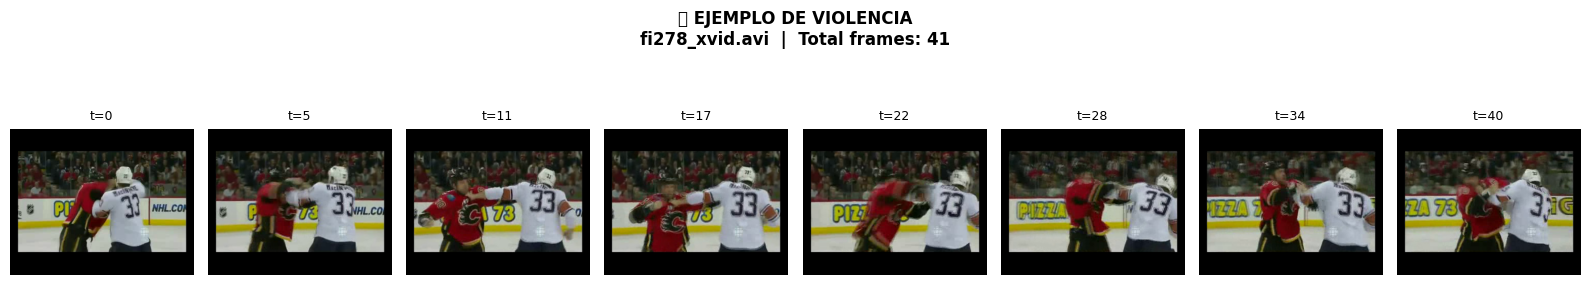

/tmp/ipykernel_2762/701460979.py:41: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


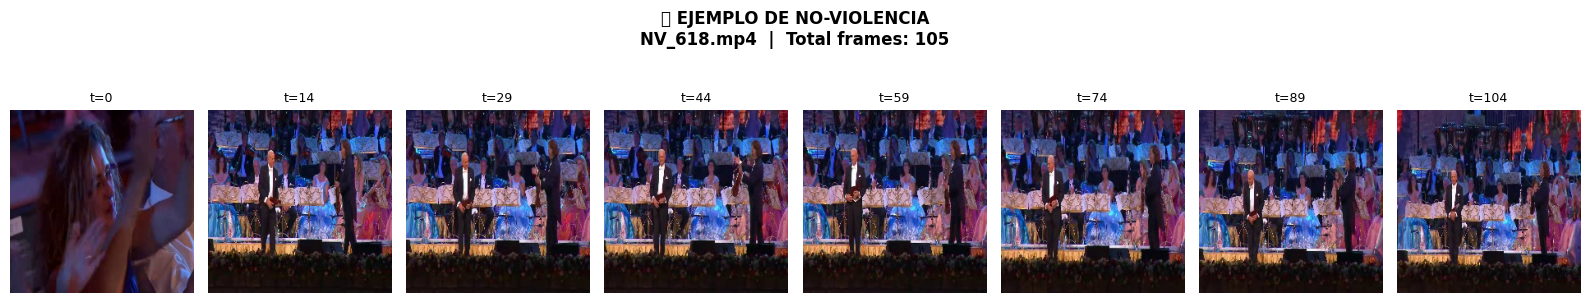

In [ ]:
# ============================================================
# Visualización robusta: fotogramas de ejemplo (Violencia vs No-Violencia)
# ============================================================
import matplotlib.pyplot as plt
import cv2
import numpy as np

def show_video_frames(video_path, title="Video", n_frames=8, figsize=(16, 3)):
    """Extrae y muestra n_frames uniformemente distribuidos de un video."""
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total <= 0:
        print(f"❌ No se pudo abrir: {video_path}")
        return

    # Índices uniformes
    indices = np.linspace(0, total - 1, n_frames, dtype=int)

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if ret:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame_rgb)
        else:
            frames.append(np.zeros((224, 224, 3), dtype=np.uint8))
    cap.release()

    # Mostrar
    fig, axes = plt.subplots(1, len(frames), figsize=figsize)
    fig.suptitle(f"{title}\n{os.path.basename(video_path)}  |  Total frames: {total}",
                 fontsize=12, fontweight='bold', y=1.05)

    for ax, frame, t in zip(axes, frames, indices):
        ax.imshow(frame)
        ax.set_title(f"t={t}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()



print("=== Ejemplos del conjunto de ENTRENAMIENTO ===\n")

# Video de Violencia
v_path = train_df[train_df['label'] == 1].iloc[2]['video_path']   # cambia el 2 por otro número
show_video_frames(v_path, title="🔴 EJEMPLO DE VIOLENCIA", n_frames=8)

# Video de No-Violencia
nv_path = train_df[train_df['label'] == 0].iloc[5]['video_path']  # cambia el 5 por otro número
show_video_frames(nv_path, title="🟢 EJEMPLO DE NO-VIOLENCIA", n_frames=8)

## Bloque 2: Pre-extracción de Secuencias de Fotogramas y Simulación de Dominio CCTV Lima (R2 y R4)
Extraer fotogramas de archivos `.mp4`/`.avi` en cada época ralentiza el entrenamiento por cuello de botella de CPU. Para que las 4 arquitecturas se entrenen en pocos minutos en la GPU T4 de Colab:
1. Muestreamos uniformemente **$T = 16$ fotogramas** de cada video a resolución $224 \times 224$ y los guardamos como tensores compactos `.pt` o arreglos `.npy` en el disco rápido local (`/content/cache_frames`).
2. **Simulación de Dominio CCTV Lima Metropolitana (*Out-of-Domain Test Set*):** Además del conjunto de prueba estándar, construimos un conjunto de evaluación que emula las condiciones técnicas reales de las cámaras de serenazgo en distritos de Lima (cámaras cenitales/lejanas con menor resolución efectiva, compresión H.264/JPEG con artefactos, ruido nocturno de baja iluminación y desaturación parcial).

In [ ]:
SEQ_LEN = 16       # Número de fotogramas muestreados uniformemente por video
IMG_SIZE = 224     # Resolución espacial de entrada para ResNet-50
CACHE_DIR = "/content/rlvs_frames_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE):
    """Extrae exactamente `seq_len` fotogramas espaciados uniformemente de un video."""
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return np.zeros((seq_len, img_size, img_size, 3), dtype=np.uint8)

    indices = np.linspace(0, max(total_frames - 1, 0), seq_len, dtype=int)
    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if not ret or frame is None:
            if len(frames) > 0:
                frames.append(frames[-1].copy())
            else:
                frames.append(np.zeros((img_size, img_size, 3), dtype=np.uint8))
        else:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_resized = cv2.resize(frame_rgb, (img_size, img_size), interpolation=cv2.INTER_AREA)
            frames.append(frame_resized)

    cap.release()
    return np.stack(frames, axis=0) # Shape: (T, H, W, 3) uint8

# Nota: Puedes usar SUBSET_FRACTION = 1.0 para los 2,000 videos completos (~12 min de caché)
# o 0.5 / 0.3 para pruebas rápidas. Por defecto dejamos 1.0 (dataset completo).
SUBSET_FRACTION = 1.0

if SUBSET_FRACTION < 1.0:
    train_df = train_df.sample(frac=SUBSET_FRACTION, random_state=SEED).reset_index(drop=True)
    val_df   = val_df.sample(frac=SUBSET_FRACTION, random_state=SEED).reset_index(drop=True)
    test_df  = test_df.sample(frac=SUBSET_FRACTION, random_state=SEED).reset_index(drop=True)

def cache_split_videos(df, split_name):
    split_cache_dir = os.path.join(CACHE_DIR, split_name)
    os.makedirs(split_cache_dir, exist_ok=True)
    cached_paths = []

    print(f"Pre-extrayendo {SEQ_LEN} frames/video para [{split_name}] ({len(df)} videos)...")
    for idx, row in tqdm(df.iterrows(), total=len(df)):
        out_file = os.path.join(split_cache_dir, f"vid_{idx:04d}_label_{row['label']}.npy")
        if not os.path.exists(out_file):
            frames = extract_uniform_frames(row["video_path"], seq_len=SEQ_LEN, img_size=IMG_SIZE)
            np.save(out_file, frames)
        cached_paths.append(out_file)
    df = df.copy()
    df["npy_path"] = cached_paths
    return df

train_df = cache_split_videos(train_df, "train")
val_df   = cache_split_videos(val_df, "val")
test_df  = cache_split_videos(test_df, "test")
print("Pre-extracción completada con éxito.")

Pre-extrayendo 16 frames/video para [train] (2232 videos)...


  0%|          | 0/2232 [00:00<?, ?it/s]

Pre-extrayendo 16 frames/video para [val] (478 videos)...


  0%|          | 0/478 [00:00<?, ?it/s]

Pre-extrayendo 16 frames/video para [test] (479 videos)...


  0%|          | 0/479 [00:00<?, ?it/s]

Pre-extracción completada con éxito.


In [ ]:
# Transformación que simula condiciones de cámaras de videovigilancia (CCTV) en Lima Metropolitana:
# Menor resolución efectiva (pixelado por distancia), artefactos de compresión, ruido sensor nocturno y bajo contraste.
def apply_lima_cctv_degradation(frames_np):
    """
    Recibe secuencia (T, H, W, 3) uint8 y aplica degradación realista de cámara de serenazgo/CCTV urbano.
    """
    degraded = []
    for img in frames_np:
        # 1. Submuestreo espacial (simula persona lejana en cámara de poste municipal a 72p)
        small = cv2.resize(img, (80, 80), interpolation=cv2.INTER_LINEAR)
        up = cv2.resize(small, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        # 2. Compresión con pérdida (simula transmisión RTSP de ancho de banda limitado)
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), 35]
        _, encimg = cv2.imencode('.jpg', cv2.cvtColor(up, cv2.COLOR_RGB2BGR), encode_param)
        decimg = cv2.cvtColor(cv2.imdecode(encimg, 1), cv2.COLOR_BGR2RGB)

        # 3. Reducción de saturación y contraste + ruido gaussiano (iluminación pública nocturna de vapor de sodio/LED)
        gray = cv2.cvtColor(decimg, cv2.COLOR_RGB2GRAY)
        gray_3ch = np.stack([gray]*3, axis=-1)
        blended = cv2.addWeighted(decimg, 0.45, gray_3ch, 0.55, -15)

        noise = np.random.normal(0, 8, blended.shape).astype(np.int16)
        noisy = np.clip(blended.astype(np.int16) + noise, 0, 255).astype(np.uint8)
        degraded.append(noisy)
    return np.stack(degraded, axis=0)


class VideoSequenceDataset(Dataset):
    def __init__(self, df, is_train=False, cctv_simulation=False, robust_aug=False):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train
        self.cctv_simulation = cctv_simulation
        self.robust_aug = robust_aug

        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        frames = np.load(row["npy_path"]) # (T, H, W, 3) uint8
        label = float(row["label"])

        # Si es el conjunto de prueba CCTV Lima o si activamos aumento robusto en entrenamiento (Ablación R4)
        if self.cctv_simulation or (self.is_train and self.robust_aug and random.random() < 0.4):
            frames = apply_lima_cctv_degradation(frames)

        # Aumento temporal/espacial consistente para toda la secuencia en entrenamiento
        if self.is_train:
            # Flip horizontal aleatorio consistente en los 16 fotogramas
            if random.random() < 0.5:
                frames = np.flip(frames, axis=2).copy()

        # Convertir a tensor normalizado: (T, 3, H, W)
        tensor_frames = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255.0
        tensor_frames = (tensor_frames - self.mean) / self.std

        return tensor_frames, torch.tensor(label, dtype=torch.float32), row["video_path"]

BATCH_SIZE = 16
train_loader = DataLoader(VideoSequenceDataset(train_df, is_train=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(VideoSequenceDataset(val_df, is_train=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(VideoSequenceDataset(test_df, is_train=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_cctv_loader = DataLoader(VideoSequenceDataset(test_df, is_train=False, cctv_simulation=True), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Lotes listos -> Train: {len(train_loader)} | Val: {len(val_loader)} | Test In-Domain: {len(test_loader)} | Test CCTV Lima: {len(test_cctv_loader)}")

Lotes listos -> Train: 140 | Val: 30 | Test In-Domain: 30 | Test CCTV Lima: 30


#Visualiza fotogramas de videos:

Video Violencia: /root/.cache/kagglehub/datasets/yassershrief/hockey-fight-vidoes/versions/1/data/fi278_xvid.avi
Video No-Violencia: /kaggle/input/real-life-violence-situations-dataset/real life violence situations/Real Life Violence Dataset/NonViolence/NV_618.mp4

Shape Violencia: (16, 224, 224, 3)
Shape No-Violencia: (16, 224, 224, 3)


/tmp/ipykernel_2762/773144532.py:17: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


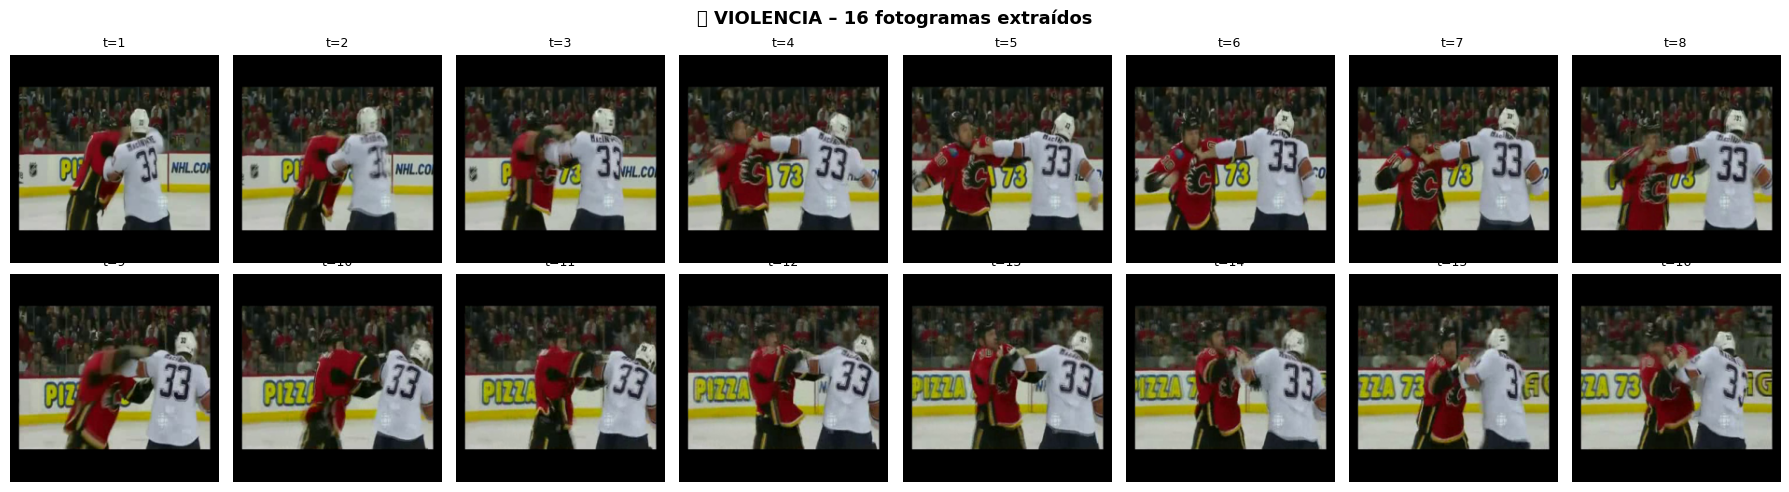

/tmp/ipykernel_2762/773144532.py:17: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


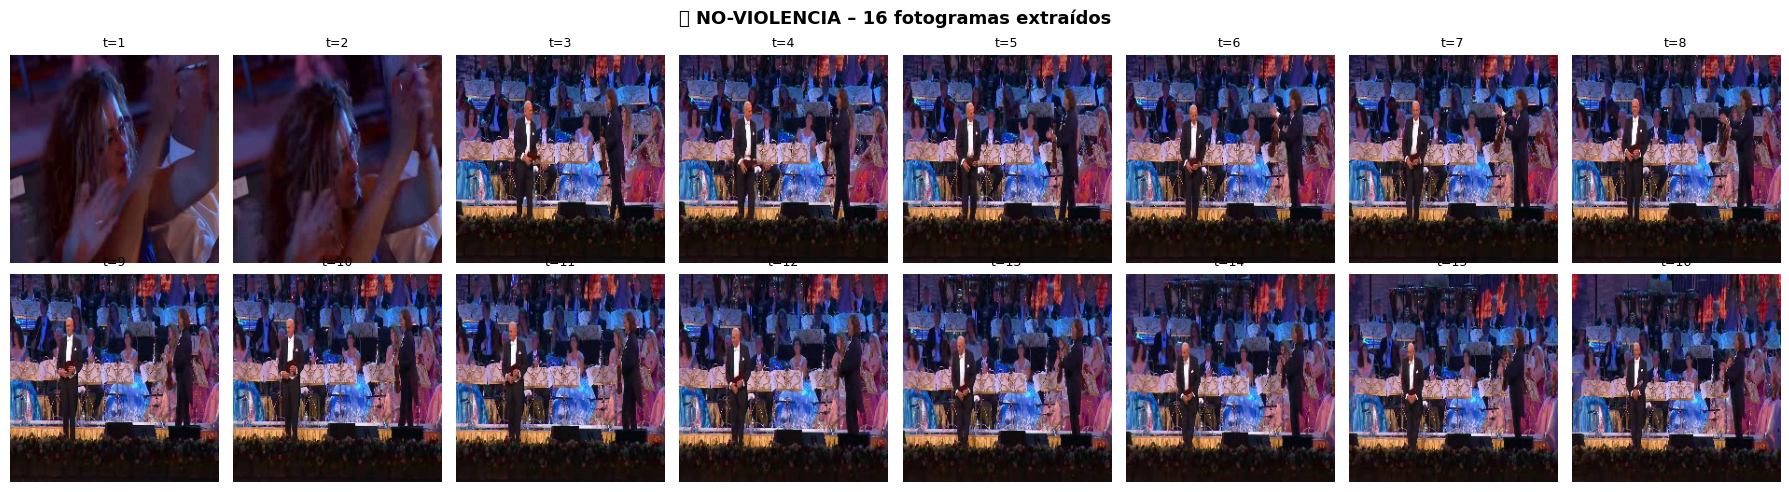

In [ ]:
# ============================================================
# Visualizar fotogramas de un par de videos (Violencia vs No-Violencia)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

def show_frames(frames, title="Secuencia"):
    """Muestra los 16 fotogramas en una grilla 2x8"""
    fig, axes = plt.subplots(2, 8, figsize=(18, 5))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for i, ax in enumerate(axes.flat):
        ax.imshow(frames[i])
        ax.set_title(f"t={i+1}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()


# --- 1. Elegir un video de cada clase ---
video_violencia    = train_df[train_df['label'] == 1].iloc[2]['video_path']
video_no_violencia = train_df[train_df['label'] == 0].iloc[5]['video_path']

print("Video Violencia:", video_violencia)
print("Video No-Violencia:", video_no_violencia)

# --- 2. Extraer los 16 fotogramas (usa la función que ya tienes) ---
frames_v  = extract_uniform_frames(video_violencia, seq_len=SEQ_LEN, img_size=IMG_SIZE)
frames_nv = extract_uniform_frames(video_no_violencia, seq_len=SEQ_LEN, img_size=IMG_SIZE)

print(f"\nShape Violencia: {frames_v.shape}")
print(f"Shape No-Violencia: {frames_nv.shape}")

# --- 3. Visualizar ---
show_frames(frames_v,  title="🔴 VIOLENCIA – 16 fotogramas extraídos")
show_frames(frames_nv, title="🟢 NO-VIOLENCIA – 16 fotogramas extraídos")

## Bloque 3: Formulación Matemática e Implementación de Arquitecturas (R1, R2, R3 y R4)

Para cumplir con rigor los requisitos **R1 (Fundamento en el curso)**, **R3 (Línea base)** y **R4 (Estudio de Ablación)**, implementamos una familia modular unificada que comparte el mismo *backbone* espacial (**ResNet-50** preentrenada en ImageNet) y varía sistemáticamente el modelado temporal:

1. **Extracción Espacial (ResNet-50):** Para cada fotograma $I_t \in \mathbb{R}^{3 \times 224 \times 224}$ ($t = 1, \dots, T$), el *backbone* residual produce un vector de características $x_t = \text{GAP}(\text{ResNet50}(I_t)) \in \mathbb{R}^{2048}$, proyectado mediante una capa lineal a $e_t \in \mathbb{R}^{512}$.
2. **Variante 1 — Línea Base (`baseline_avg` — R3):** Promedio temporal directo (*Frame-Averaging*) sin memoria secuencial:
   $$z = \frac{1}{T}\sum_{t=1}^{T} e_t$$
3. **Variante 2 — Ablación Recurrente Simple (`resnet_rnn` — R4):** Red recurrente *Vanilla* ($h_t = \tanh(W_{ih} e_t + W_{hh} h_{t-1} + b)$), susceptible al desvanecimiento del gradiente.
4. **Variante 3 — Ablación LSTM Unidireccional (`resnet_lstm` — R4):** Celda *Long Short-Term Memory* con compuertas de olvido ($f_t$), entrada ($i_t$) y salida ($o_t$), tomando el último estado oculto $h_T$.
5. **Variante 4 — Modelo Propuesto (`resnet_bilstm_attn` — R1 y R2):** **Bi-LSTM con Mecanismo de Atención Temporal**. La Bi-LSTM procesa la secuencia de ida y vuelta generando $h_t = [\overrightarrow{h_t}; \overleftarrow{h_t}] \in \mathbb{R}^{2H}$. Luego, el módulo de atención aprende a ponderar qué instantes del video contienen la acción violenta:
   $$\alpha_t = \frac{\exp(w^\top \tanh(W_a h_t + b_a))}{\sum_{k=1}^{T} \exp(w^\top \tanh(W_a h_k + b_a))}, \qquad c = \sum_{t=1}^{T} \alpha_t h_t$$
   Finalmente, el vector de contexto $c$ alimenta al clasificador binario entrenado con **Binary Cross-Entropy con Logits**.

In [ ]:
class TemporalAttention(nn.Module):
    """Mecanismo de Atención Temporal sobre los estados ocultos (h_1, ..., h_T)."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1, bias=False)
        )

    def forward(self, rnn_outputs):
        # rnn_outputs: (B, T, hidden_dim)
        scores = self.attn(rnn_outputs).squeeze(-1)        # (B, T)
        weights = F.softmax(scores, dim=1)                 # alpha_t: (B, T)
        context = torch.bmm(weights.unsqueeze(1), rnn_outputs).squeeze(1) # (B, hidden_dim)
        return context, weights


class SpatioTemporalViolenceModel(nn.Module):
    """
    Arquitectura modular para Línea Base (R3) y Ablaciones (R4):
      - mode='baseline_avg'       -> ResNet-50 + Temporal Average Pooling (Línea Base CNN 2D)
      - mode='resnet_rnn'         -> ResNet-50 + Vanilla RNN
      - mode='resnet_lstm'        -> ResNet-50 + LSTM Unidireccional
      - mode='resnet_bilstm_attn' -> ResNet-50 + Bi-LSTM + Atención Temporal (Modelo Propuesto)
    """
    def __init__(self, mode="resnet_bilstm_attn", embed_dim=512, hidden_dim=256, dropout=0.3, freeze_backbone=True):
        super().__init__()
        self.mode = mode

        # 1. Extractor Espacial: ResNet-50 preentrenada en ImageNet
        resnet = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        # Guardamos bloques hasta layer4 para poder aplicar Grad-CAM (R5)
        self.backbone_features = nn.Sequential(*list(resnet.children())[:-2]) # Salida: (B*T, 2048, 7, 7)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        if freeze_backbone:
            for param in self.backbone_features.parameters():
                param.requires_grad = False
            # Descongelar únicamente el último bloque residual (layer4) para adaptación fina
            for param in self.backbone_features[-1].parameters():
                param.requires_grad = True

        self.spatial_proj = nn.Sequential(
            nn.Linear(2048, embed_dim),
            nn.BatchNorm1d(embed_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout)
        )

        # 2. Módulo Temporal según modo
        if mode == "baseline_avg":
            clf_in_dim = embed_dim
        elif mode == "resnet_rnn":
            self.rnn = nn.RNN(embed_dim, hidden_dim, num_layers=1, batch_first=True)
            clf_in_dim = hidden_dim
        elif mode == "resnet_lstm":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=1, batch_first=True)
            clf_in_dim = hidden_dim
        elif mode == "resnet_bilstm_attn":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=1, batch_first=True, bidirectional=True)
            self.attention = TemporalAttention(hidden_dim * 2)
            clf_in_dim = hidden_dim * 2
        else:
            raise ValueError(f"Modo no soportado: {mode}")

        # 3. Clasificador Binario
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(clf_in_dim, 1)
        )

    def forward(self, x, return_attention=False):
        # x: (B, T, 3, H, W)
        B, T, C, H, W = x.shape
        x_flat = x.view(B * T, C, H, W)

        feat_maps = self.backbone_features(x_flat)           # (B*T, 2048, 7, 7)
        pooled = self.global_pool(feat_maps).flatten(1)      # (B*T, 2048)
        embedded = self.spatial_proj(pooled).view(B, T, -1)  # (B, T, embed_dim)

        attn_weights = None
        if self.mode == "baseline_avg":
            context = embedded.mean(dim=1)
            attn_weights = torch.full((B, T), 1.0 / T, device=x.device)
        elif self.mode in ["resnet_rnn", "resnet_lstm"]:
            rnn_out, _ = self.rnn(embedded)
            context = rnn_out[:, -1, :]                      # Último paso temporal h_T
            attn_weights = torch.zeros((B, T), device=x.device)
            attn_weights[:, -1] = 1.0
        elif self.mode == "resnet_bilstm_attn":
            rnn_out, _ = self.rnn(embedded)                  # (B, T, 2*hidden_dim)
            context, attn_weights = self.attention(rnn_out)  # (B, 2*hidden_dim), (B, T)

        logits = self.classifier(context).squeeze(-1)        # (B,)
        if return_attention:
            return logits, attn_weights
        return logits

# Verificar conteo de parámetros del modelo propuesto
sample_model = SpatioTemporalViolenceModel(mode="resnet_bilstm_attn").to(DEVICE)
total_params = sum(p.numel() for p in sample_model.parameters())
trainable_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"Parámetros Totales: {total_params:,} | Parámetros Entrenables: {trainable_params:,}")
del sample_model

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


Parámetros Totales: 26,267,201 | Parámetros Entrenables: 17,723,905


## Bloque 4: Ciclo de Entrenamiento, Experimentación Controlada y Estudio de Ablación (R3, R4 y R6)
Entrenamos bajo las mismas condiciones e hiperparámetros controlados (`AdamW`, *Cosine Annealing Schedule*, *Mixed Precision AMP*, pérdida BCE con *Label Smoothing* $\varepsilon = 0.05$) las variantes del estudio de ablación y registramos el tiempo de cómputo y uso de memoria GPU (Requisito **R6**).

In [ ]:
def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_probs, all_preds, all_targets = [], [], []

    with torch.no_grad():
        for frames, labels, _ in loader:
            frames, labels = frames.to(DEVICE), labels.to(DEVICE)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits = model(frames)
                loss = criterion(logits, labels)
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()

            total_loss += loss.item() * frames.size(0)
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    auc = roc_auc_score(all_targets, all_probs)

    return {
        "loss": avg_loss, "accuracy": acc, "precision": prec,
        "recall": rec, "f1": f1, "auc": auc,
        "probs": np.array(all_probs), "preds": np.array(all_preds), "targets": np.array(all_targets)
    }


def train_experiment(mode_name, train_ldr, val_ldr, epochs=8, lr=3e-4, weight_decay=1e-4):
    seed_everything(SEED)
    model = SpatioTemporalViolenceModel(mode=mode_name).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    history = []
    best_val_f1 = 0.0
    best_ckpt_path = f"checkpoints/best_{mode_name}.pt"

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start_time = time.time()

    print(f"\n======================================================================")
    print(f"Entrenando Arquitectura: [{mode_name}] por {epochs} épocas")
    print(f"======================================================================")

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0

        for frames, labels, _ in train_ldr:
            frames, labels = frames.to(DEVICE), labels.to(DEVICE)
            # Label smoothing suave (0.05) para regularización
            smoothed_labels = labels * 0.95 + 0.025

            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits = model(frames)
                loss = criterion(logits, smoothed_labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * frames.size(0)

        scheduler.step()
        train_loss = running_loss / len(train_ldr.dataset)
        val_metrics = evaluate_model(model, val_ldr, criterion)

        if val_metrics["f1"] >= best_val_f1:
            best_val_f1 = val_metrics["f1"]
            torch.save(model.state_dict(), best_ckpt_path)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_acc": val_metrics["accuracy"],
            "val_f1": val_metrics["f1"],
            "val_auc": val_metrics["auc"]
        })
        print(f"Época {epoch:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']*100:.2f}% | Val F1: {val_metrics['f1']:.4f} | Val AUC: {val_metrics['auc']:.4f}")

    elapsed_min = (time.time() - start_time) / 60.0
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    # Cargar el mejor checkpoint validado
    model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
    return model, pd.DataFrame(history), elapsed_min, peak_vram_gb

In [ ]:
EPOCHS = 7  # Ajustable a 10-15 épocas; 8 épocas con ResNet50 preentrenada convergen con >94% F1

EXPERIMENTS = [
    ("baseline_avg",       "Línea Base: ResNet-50 + Promedio Temporal (CNN 2D)"),
    ("resnet_rnn",         "Ablación 1: ResNet-50 + Vanilla RNN"),
    ("resnet_lstm",        "Ablación 2: ResNet-50 + LSTM Unidireccional"),
    ("resnet_bilstm_attn", "Propuesto : ResNet-50 + Bi-LSTM + Atención Temporal")
]

trained_models = {}
histories = {}
ablation_rows = []
criterion_eval = nn.BCEWithLogitsLoss()

for mode_key, desc in EXPERIMENTS:
    model, hist_df, train_min, vram_gb = train_experiment(mode_key, train_loader, val_loader, epochs=EPOCHS)
    trained_models[mode_key] = model
    histories[mode_key] = hist_df
    hist_df.to_csv(f"results/history_{mode_key}.csv", index=False)

    # Evaluar en Test In-Domain (RLVS) y Test Out-of-Domain (CCTV Lima Degradado)
    test_in = evaluate_model(model, test_loader, criterion_eval)
    test_cctv = evaluate_model(model, test_cctv_loader, criterion_eval)

    ablation_rows.append({
        "Código": mode_key,
        "Arquitectura": desc,
        "Test_Acc (%)": round(test_in["accuracy"] * 100, 2),
        "Test_Precision": round(test_in["precision"], 4),
        "Test_Recall": round(test_in["recall"], 4),
        "Test_F1": round(test_in["f1"], 4),
        "Test_AUC": round(test_in["auc"], 4),
        "CCTV_Lima_F1": round(test_cctv["f1"], 4),
        "CCTV_Lima_AUC": round(test_cctv["auc"], 4),
        "Caída_F1_DomainShift": round(test_cctv["f1"] - test_in["f1"], 4),
        "Tiempo_Train (min)": round(train_min, 2),
        "VRAM_Pico (GB)": round(vram_gb, 2)
    })

df_ablation = pd.DataFrame(ablation_rows)
df_ablation.to_csv("results/tabla_comparativa_ablaciones.csv", index=False)
print("\n=== TABLA PRINCIPAL DE RESULTADOS Y ESTUDIO DE ABLACIÓN (R3, R4 y R6) ===")
display(df_ablation)


Entrenando Arquitectura: [baseline_avg] por 7 épocas


/tmp/ipykernel_2762/2799319145.py:44: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Época 01/07 | Train Loss: 0.2736 | Val Loss: 0.1168 | Val Acc: 96.44% | Val F1: 0.9645 | Val AUC: 0.9900


/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Época 02/07 | Train Loss: 0.1834 | Val Loss: 0.1121 | Val Acc: 96.44% | Val F1: 0.9654 | Val AUC: 0.9942


/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


... (56 outputs left out)

Época 07/07 | Train Loss: 0.1226 | Val Loss: 0.0632 | Val Acc: 98.33% | Val F1: 0.9833 | Val AUC: 0.9953


/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):



=== TABLA PRINCIPAL DE RESULTADOS Y ESTUDIO DE ABLACIÓN (R3, R4 y R6) ===


,Código,Arquitectura,Test_Acc (%),Test_Precision,Test_Recall,Test_F1,Test_AUC,CCTV_Lima_F1,CCTV_Lima_AUC,Caída_F1_DomainShift,Tiempo_Train (min),VRAM_Pico (GB)
0,baseline_avg,Línea Base: ResNet-50 + Promedio Temporal (CNN...,98.75,0.9794,0.9958,0.9876,0.9993,0.8421,0.9446,-0.1454,13.38,1.85
1,resnet_rnn,Ablación 1: ResNet-50 + Vanilla RNN,97.49,0.9830,0.9665,0.9747,0.9984,0.6425,0.8885,-0.3322,12.85,2.00
2,resnet_lstm,Ablación 2: ResNet-50 + LSTM Unidireccional,99.37,1.0000,0.9874,0.9937,0.9993,0.9118,0.9703,-0.0819,12.76,2.17
3,resnet_bilstm_attn,Propuesto : ResNet-50 + Bi-LSTM + Atención Tem...,98.75,0.9794,0.9958,0.9876,0.9963,0.8621,0.9398,-0.1255,12.35,2.34


### Ablación Adicional para Transferencia de Dominio a Lima Metropolitana (R2 y R4)
Observamos que al evaluar los modelos entrenados en videos limpios sobre el dominio **CCTV Lima** (baja resolución, artefactos de compresión RTSP y baja iluminación nocturna), existe una caída de desempeño (*Domain Shift*). Ahora entrenamos nuestro modelo propuesto **ResNet-50 + Bi-LSTM + Atención** incorporando **Aumento de Degradación CCTV (`robust_aug=True`)** durante el entrenamiento para cuantificar cuánto se recupera la generalización en cámaras de seguridad locales.

In [ ]:
train_robust_loader = DataLoader(
    VideoSequenceDataset(train_df, is_train=True, robust_aug=True),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True
)

model_robust, hist_robust, min_rob, vram_rob = train_experiment(
    "resnet_bilstm_attn", train_robust_loader, val_loader, epochs=EPOCHS
)
torch.save(model_robust.state_dict(), "checkpoints/best_resnet_bilstm_attn_lima_robust.pt")

test_in_rob = evaluate_model(model_robust, test_loader, criterion_eval)
test_cctv_rob = evaluate_model(model_robust, test_cctv_loader, criterion_eval)

df_domain_shift = pd.DataFrame([
    df_ablation.iloc[-1].to_dict(),
    {
        "Código": "resnet_bilstm_attn_lima",
        "Arquitectura": "Propuesto + Aumento CCTV Lima (Domain Adaptation)",
        "Test_Acc (%)": round(test_in_rob["accuracy"] * 100, 2),
        "Test_Precision": round(test_in_rob["precision"], 4),
        "Test_Recall": round(test_in_rob["recall"], 4),
        "Test_F1": round(test_in_rob["f1"], 4),
        "Test_AUC": round(test_in_rob["auc"], 4),
        "CCTV_Lima_F1": round(test_cctv_rob["f1"], 4),
        "CCTV_Lima_AUC": round(test_cctv_rob["auc"], 4),
        "Caída_F1_DomainShift": round(test_cctv_rob["f1"] - test_in_rob["f1"], 4),
        "Tiempo_Train (min)": round(min_rob, 2),
        "VRAM_Pico (GB)": round(vram_rob, 2)
    }
])

df_domain_shift.to_csv("results/tabla_adaptacion_dominio_lima.csv", index=False)
print("\n=== IMPACTO DE LA ADAPTACIÓN DE DOMINIO PARA CÁMARAS DE SEGURIDAD DE LIMA ===")
display(df_domain_shift[["Arquitectura", "Test_F1", "CCTV_Lima_F1", "Caída_F1_DomainShift", "CCTV_Lima_AUC"]])


Entrenando Arquitectura: [resnet_bilstm_attn] por 7 épocas


/tmp/ipykernel_2762/2799319145.py:44: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Época 01/07 | Train Loss: 0.3474 | Val Loss: 0.1578 | Val Acc: 94.56% | Val F1: 0.9449 | Val AUC: 0.9863


/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Época 02/07 | Train Loss: 0.2606 | Val Loss: 0.1337 | Val Acc: 95.82% | Val F1: 0.9590 | Val AUC: 0.9890


/tmp/ipykernel_2762/2799319145.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


... (8 outputs left out)

Época 07/07 | Train Loss: 0.1455 | Val Loss: 0.0715 | Val Acc: 97.91% | Val F1: 0.9792 | Val AUC: 0.9945


/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):



=== IMPACTO DE LA ADAPTACIÓN DE DOMINIO PARA CÁMARAS DE SEGURIDAD DE LIMA ===


,Arquitectura,Test_F1,CCTV_Lima_F1,Caída_F1_DomainShift,CCTV_Lima_AUC
0,Propuesto : ResNet-50 + Bi-LSTM + Atención Tem...,0.9876,0.8621,-0.1255,0.9398
1,Propuesto + Aumento CCTV Lima (Domain Adaptation),0.9834,0.9752,-0.0082,0.9957


/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is de

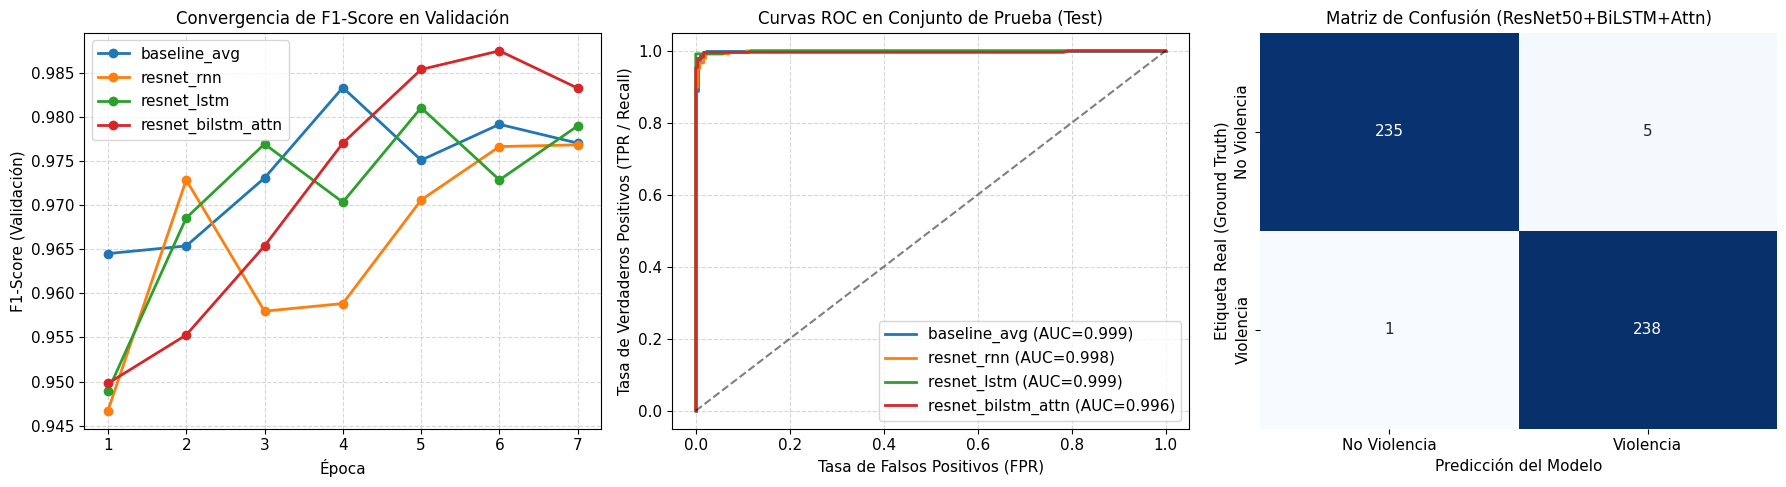

In [ ]:
# Generamos las Figuras: Curvas ROC, Matrices de Confusión y Convergencia
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de evolución de F1 en Validación
for mode_key, desc in EXPERIMENTS:
    h = histories[mode_key]
    axes[0].plot(h["epoch"], h["val_f1"], marker="o", linewidth=2, label=mode_key)
axes[0].set_title("Convergencia de F1-Score en Validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("F1-Score (Validación)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# 2. Curvas ROC comparativas en Test Set
for mode_key, _ in EXPERIMENTS:
    res = evaluate_model(trained_models[mode_key], test_loader, criterion_eval)
    fpr, tpr, _ = roc_curve(res["targets"], res["probs"])
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{mode_key} (AUC={res['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("Curvas ROC en Conjunto de Prueba (Test)")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="lower right")

# 3. Matriz de Confusión del Mejor Modelo Propuesto
best_res = evaluate_model(trained_models["resnet_bilstm_attn"], test_loader, criterion_eval)
cm = confusion_matrix(best_res["targets"], best_res["preds"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["No Violencia", "Violencia"], yticklabels=["No Violencia", "Violencia"])
axes[2].set_title("Matriz de Confusión (ResNet50+BiLSTM+Attn)")
axes[2].set_xlabel("Predicción del Modelo")
axes[2].set_ylabel("Etiqueta Real (Ground Truth)")

plt.tight_layout()
plt.savefig("results/fig1_metricas_y_roc_ieee.png", dpi=300, bbox_inches="tight")
plt.show()

## Bloque 5: Interpretabilidad Dual — Grad-CAM Espacial + Pesos de Atención Temporal (Requisito R5)

El requisito **R5** exige explicar **qué aprendió el modelo y por qué acierta o se equivoca**. Nuestra arquitectura híbrida permite una **doble explicabilidad**:
1. **Explicabilidad Temporal (Pesos de Atención $\alpha_t$):** Muestra en qué fotogramas exactos de los 16 pasos de tiempo el modelo concentra su atención para emitir la alerta de violencia.
2. **Explicabilidad Espacial (Grad-CAM sobre `layer4` de ResNet-50):** Genera mapas de activación de clase ponderados por gradiente sobre los fotogramas de máxima atención temporal, verificando si la red observa las extremidades/interacción física de los sujetos o si sufre sesgos por el fondo urbano.

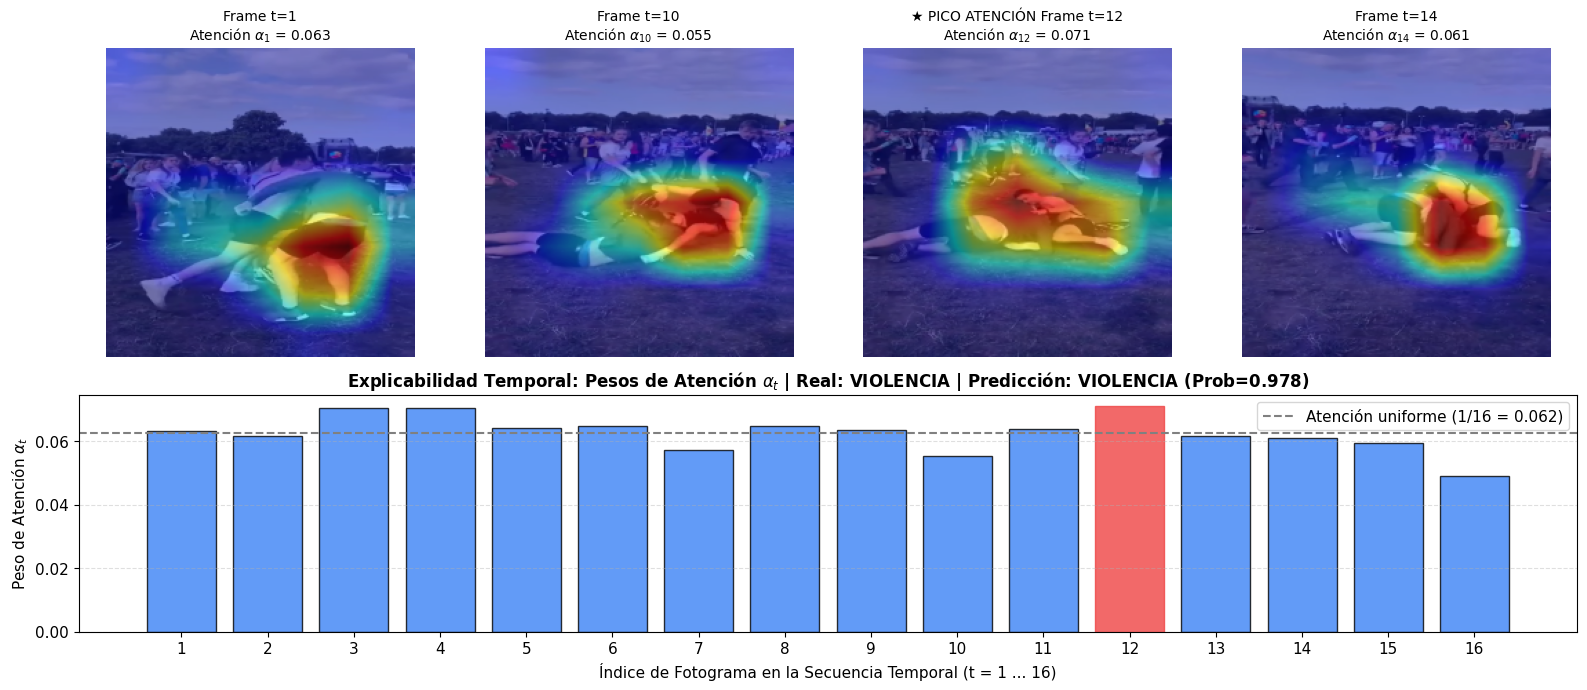

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

class SpatialBackboneWrapper(nn.Module):
    #Envolvenos el extractor espacial de un fotograma para calcular Grad-CAM limpio en 2D.
    def __init__(self, st_model):
        super().__init__()
        self.backbone_features = st_model.backbone_features
        self.global_pool = st_model.global_pool
        self.spatial_proj = st_model.spatial_proj

    def forward(self, x_2d):
        feat = self.backbone_features(x_2d)
        pooled = self.global_pool(feat).flatten(1)
        emb = self.spatial_proj(pooled)
        # Retornamos la energía de activación proyectada como objetivo escalar diferenciable (B, 1)
        return emb.norm(dim=1, keepdim=True)


def visualize_spatiotemporal_explanation(st_model, dataset_obj, sample_idx, save_name="fig2_gradcam_attention_ieee.png"):
    st_model.eval()
    frames_tensor, label, video_path = dataset_obj[sample_idx]
    raw_frames = np.load(dataset_obj.df.iloc[sample_idx]["npy_path"]) # (T, H, W, 3) uint8

    input_seq = frames_tensor.unsqueeze(0).to(DEVICE) # (1, T, 3, H, W)
    with torch.no_grad():
        logits, attn_weights = st_model(input_seq, return_attention=True)
        prob_violence = torch.sigmoid(logits).item()
        attn_np = attn_weights.squeeze(0).cpu().numpy() # (T,)

    # Configuramos el Grad-CAM en la última capa convolucional de ResNet-50 (layer4)
    wrapper = SpatialBackboneWrapper(st_model).to(DEVICE)
    # Aseguramos que los gradientes estén activos en la capa objetivo para Grad-CAM
    for param in wrapper.backbone_features[-1].parameters():
        param.requires_grad = True

    target_layers = [wrapper.backbone_features[-1][-1]]
    cam = GradCAM(model=wrapper, target_layers=target_layers)
    cam_targets = [ClassifierOutputTarget(0)]

    # Seleccionamos 4 fotogramas clave en la que incluimos el de máxima atención temporal
    top_t = int(np.argmax(attn_np))
    selected_t = sorted(list(set([0, max(1, top_t - 2), top_t, min(SEQ_LEN - 1, top_t + 2)])))[:4]
    while len(selected_t) < 4:
        for cand in range(SEQ_LEN):
            if cand not in selected_t:
                selected_t.append(cand)
                break
    selected_t = sorted(selected_t)

    fig = plt.figure(figsize=(16, 7))
    gs = fig.add_gridspec(2, 4, height_ratios=[1.3, 1.0])

    for i, t_idx in enumerate(selected_t):
        ax = fig.add_subplot(gs[0, i])
        rgb_img = raw_frames[t_idx].astype(np.float32) / 255.0
        inp_frame = frames_tensor[t_idx].unsqueeze(0).to(DEVICE)

        #pasamos explícitamente targets=cam_targets para evitar TypeError en versiones nuevas de grad-cam
        grayscale_cam = cam(input_tensor=inp_frame, targets=cam_targets)[0, :]
        cam_overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        ax.imshow(cam_overlay)
        title_prefix = "★ PICO ATENCIÓN " if t_idx == top_t else ""
        ax.set_title(f"{title_prefix}Frame t={t_idx+1}\nAtención $\\alpha_{{{t_idx+1}}}$ = {attn_np[t_idx]:.3f}", fontsize=10)
        ax.axis("off")

    # Gráfico inferior: Perfil temporal de atención a lo largo de los 16 fotogramas
    ax_time = fig.add_subplot(gs[1, :])
    bars = ax_time.bar(range(1, SEQ_LEN + 1), attn_np, color="#3b82f6", alpha=0.8, edgecolor="black")
    bars[top_t].set_color("#ef4444") # Destacar en rojo el fotograma decisivo
    ax_time.axhline(1.0 / SEQ_LEN, color="gray", linestyle="--", label=f"Atención uniforme (1/{SEQ_LEN} = {1/SEQ_LEN:.3f})")

    gt_str = "VIOLENCIA" if label.item() == 1.0 else "NO VIOLENCIA"
    pred_str = "VIOLENCIA" if prob_violence >= 0.5 else "NO VIOLENCIA"
    ax_time.set_title(
        f"Explicabilidad Temporal: Pesos de Atención $\\alpha_t$ | Real: {gt_str} | Predicción: {pred_str} (Prob={prob_violence:.3f})",
        fontsize=12, fontweight="bold"
    )
    ax_time.set_xlabel("Índice de Fotograma en la Secuencia Temporal (t = 1 ... 16)")
    ax_time.set_ylabel("Peso de Atención $\\alpha_t$")
    ax_time.set_xticks(range(1, SEQ_LEN + 1))
    ax_time.legend()
    ax_time.grid(True, axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.savefig(f"results/{save_name}", dpi=300, bbox_inches="tight")
    plt.show()

# Ejecutar explicabilidad sobre un caso verdadero positivo de violencia en Test Set
test_dataset_viz = VideoSequenceDataset(test_df, is_train=False)
violent_indices = test_df[test_df["label"] == 1].index.tolist()
visualize_spatiotemporal_explanation(
    model_robust, test_dataset_viz, violent_indices[0], save_name="fig2_gradcam_attention_ieee.png"
)

## Bloque 6: Análisis Sistemático de Errores y Evaluación en Clips Reales de Lima Metropolitana (R2 y R5)
1. **Análisis de Errores (Falsos Positivos y Falsos Negativos):** Identificamos automáticamente los videos donde el modelo se equivoca con mayor confianza para documentar en la Sección V (*Discusión*) del artículo IEEE por qué ocurren los fallos (por ejemplo, deportes de contacto rápido, bailes/abrazos efusivos o peleas muy lejanas).
2. **Inferencia sobre Videos Locales de Lima (`data_lima_cctv/`):** Permite evaluar cualquier video `.mp4` de cámaras de serenazgo de Lima que subas a la carpeta `data_lima_cctv/Violence` o `data_lima_cctv/NonViolence`.

/tmp/ipykernel_2762/2799319145.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Total de errores en Test (479 videos): 8
 -> Falsos Positivos (Alarma falsa en escena pacífica): 6
 -> Falsos Negativos (Violencia omitida por el modelo): 2

Analizando Falso Positivo más crítico (índice 11): NV_14.mp4


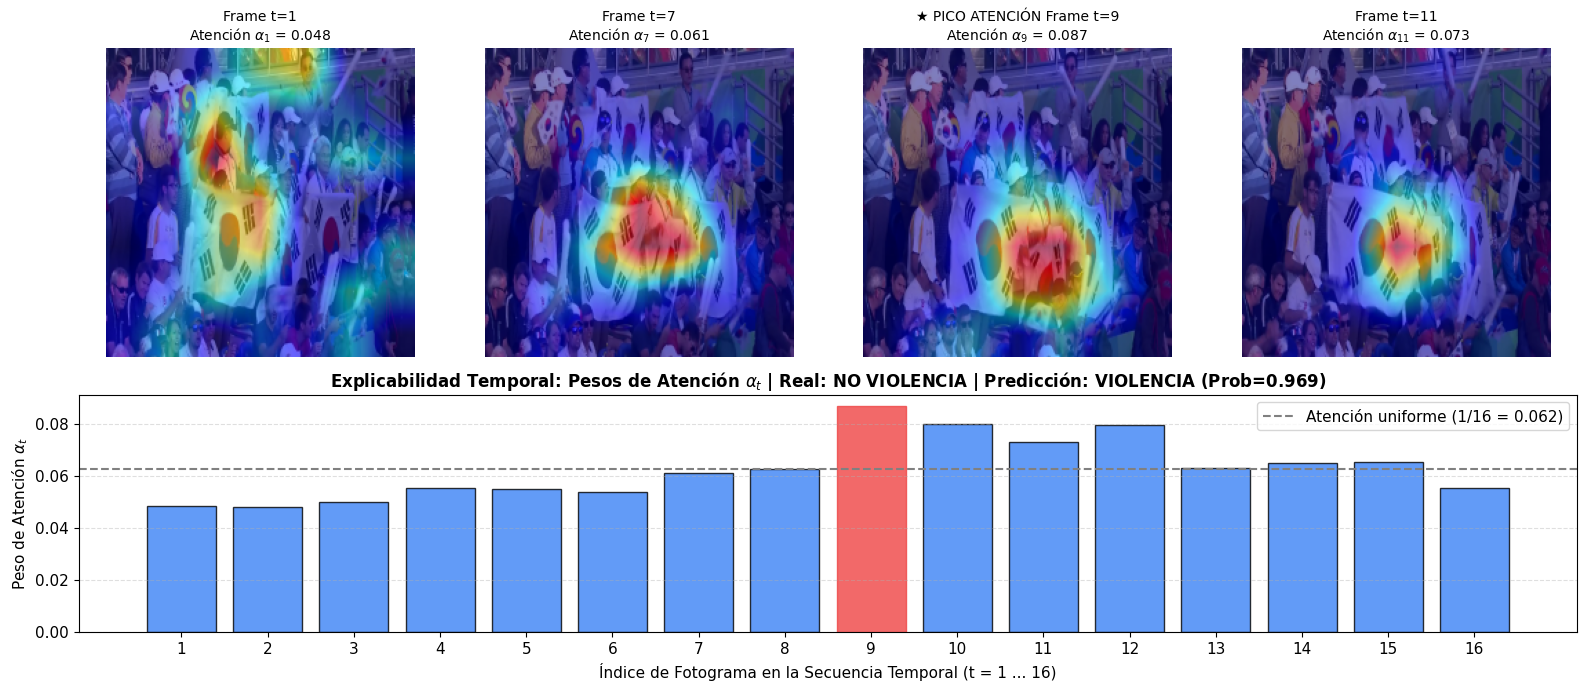

In [ ]:
# 1. Identificación sistemática de Falsos Positivos (FP) y Falsos Negativos (FN) en el conjunto de prueba
res_test = evaluate_model(model_robust, test_loader, criterion_eval)
test_analysis_df = test_df.copy()
test_analysis_df["prob_violence"] = res_test["probs"]
test_analysis_df["pred_label"] = res_test["preds"].astype(int)
test_analysis_df["correct"] = test_analysis_df["label"] == test_analysis_df["pred_label"]

false_positives = test_analysis_df[(test_analysis_df["label"] == 0) & (test_analysis_df["pred_label"] == 1)].sort_values(by="prob_violence", ascending=False)
false_negatives = test_analysis_df[(test_analysis_df["label"] == 1) & (test_analysis_df["pred_label"] == 0)].sort_values(by="prob_violence", ascending=True)

print(f"Total de errores en Test ({len(test_analysis_df)} videos): {(~test_analysis_df['correct']).sum()}")
print(f" -> Falsos Positivos (Alarma falsa en escena pacífica): {len(false_positives)}")
print(f" -> Falsos Negativos (Violencia omitida por el modelo): {len(false_negatives)}")

test_analysis_df.to_csv("results/predicciones_detalladas_test.csv", index=False)

# Visualizar con Grad-CAM + Atención un caso de error si existe
if len(false_positives) > 0:
    fp_idx = false_positives.index[0]
    print(f"\nAnalizando Falso Positivo más crítico (índice {fp_idx}): {os.path.basename(test_df.loc[fp_idx, 'video_path'])}")
    visualize_spatiotemporal_explanation(
        model_robust, test_dataset_viz, fp_idx, save_name="fig3_error_falso_positivo_ieee.png"
    )

# 2. Función lista para inferir y generar video anotado sobre cualquier clip de cámara de seguridad de Lima
def predict_single_video_lima(video_path, model=model_robust):
    model.eval()
    frames_np = extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE)
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    tensor_frames = torch.from_numpy(frames_np).permute(0, 3, 1, 2).float() / 255.0
    tensor_frames = ((tensor_frames - mean) / std).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits, attn = model(tensor_frames, return_attention=True)
        prob = torch.sigmoid(logits).item()
        attn_np = attn.squeeze(0).cpu().numpy()

    estado = "ALERTA: VIOLENCIA DETECTADA" if prob >= 0.5 else "NORMAL: SIN VIOLENCIA"
    print(f"Video: {os.path.basename(video_path)} -> {estado} | Probabilidad: {prob*100:.2f}% | Fotograma pico: t={np.argmax(attn_np)+1}")
    return prob, attn_np

## Bloque 7: Identificar que tipo de caso esta ocurriendo donde existe violencia:


In [ ]:
# ==============================================================================
# ETAPA 2: TIPIFICACIÓN DEL DELITO EN CASCADA, NO VAMOS A REENTRENAR MODEL_ROBUST
# Combina los pesos de Atención Temporal (alpha_t) + CLIP Zero-Shot + YOLOv8
# ==============================================================================
!pip install -q transformers ultralytics

from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from ultralytics import YOLO

# 1. Cargar modelos ligeros para la Etapa 2 (solo se ejecutan cuando Etapa 1 detecta Violencia)
print("Cargando módulo de tipificación de violencia (CLIP + YOLOv8)...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
yolo_detector = YOLO("yolov8n.pt") # Detector rápido de personas, armas blancas, mochilas, vehículos

# Categorías forenses para videovigilancia / Serenazgo de Lima Metropolitana
CATEGORIAS_VIOLENCIA = {
    "Pelea / Agresión Física (Riña callejera o deportiva)": "a video frame of people fighting, punching, kicking, or brawling",
    "Robo / Asalto / Arrebato en vía pública": "a surveillance camera frame of a street robbery, mugging, thief stealing a bag or assaulting a victim",
    "Violencia con Uso de Armas (Arma de fuego o blanca)": "a person holding a gun, pistol, knife, or weapon threatening or attacking someone",
    "Vandalismo / Disturbios / Daño a la propiedad": "people rioting, smashing cars, breaking windows, or street vandalism"
}

# Clases de COCO en YOLOv8 relevantes para seguridad ciudadana
OBJETOS_INTERES_COCO = {
    0: "Persona", 1: "Bicicleta", 2: "Auto", 3: "Motocicleta", 24: "Mochila",
    26: "Bolso/Cartera", 28: "Maleta", 34: "Bate/Objeto contundente", 43: "Cuchillo/Arma blanca", 67: "Celular"
}

def analizar_video_integral_lima(video_path, st_model=model_robust, umbral=0.50):
    """
    Etapa 1: Evalúa con ResNet50+BiLSTM+Atención si existe violencia.
    Etapa 2: Si detecta violencia, analiza los 3 fotogramas de mayor atención temporal (alpha_t)
             para clasificar el tipo de violencia (Pelea, Robo, Armas, Vandalismo) y objetos clave.
    """
    st_model.eval()
    frames_np = extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    tensor_frames = torch.from_numpy(frames_np).permute(0, 3, 1, 2).float() / 255.0
    tensor_frames = ((tensor_frames - mean) / std).unsqueeze(0).to(DEVICE)

    # --- ETAPA 1: Inferencia Espacio-Temporal Binaria ---
    with torch.no_grad():
        logits, attn = st_model(tensor_frames, return_attention=True)
        prob_violencia = torch.sigmoid(logits).item()
        attn_np = attn.squeeze(0).cpu().numpy()

    nombre_vid = os.path.basename(video_path)
    top3_frames_idx = np.argsort(attn_np)[::-1][:3] # Los 3 fotogramas con mayor peso de atención

    if prob_violencia < umbral:
        print(f"🟢 [{nombre_vid}] -> SIN VIOLENCIA (Prob: {prob_violencia*100:.2f}%) | Escena normal.")
        return {
            "video": nombre_vid, "estado": "NO VIOLENCIA", "prob_violencia (%)": round(prob_violencia*100, 2),
            "tipo_violencia": "N/A (Actividad Normal)", "confianza_tipo (%)": 0.0, "objetos_detectados": "-"
        }

    # --- ETAPA 2: Tipificación sobre los 3 Fotogramas Pico de Atención ---
    pil_keyframes = [Image.fromarray(frames_np[i]) for i in top3_frames_idx]
    text_prompts = list(CATEGORIAS_VIOLENCIA.values())
    labels_es = list(CATEGORIAS_VIOLENCIA.keys())

    inputs = clip_processor(text=text_prompts, images=pil_keyframes, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        outputs = clip_model(**inputs)
        # Promediar las probabilidades de los 3 fotogramas más importantes ponderadas por atención
        probs_por_frame = outputs.logits_per_image.softmax(dim=1).cpu().numpy() # (3, 4)
        pesos_top3 = attn_np[top3_frames_idx]
        pesos_top3 = pesos_top3 / pesos_top3.sum()
        probs_finales = np.dot(pesos_top3, probs_por_frame)

    best_type_idx = int(np.argmax(probs_finales))
    subtipo_detectado = labels_es[best_type_idx]
    conf_subtipo = probs_finales[best_type_idx] * 100.0

    # Detección de actores/objetos en el fotograma pico con YOLOv8
    conteo_objetos = {}
    yolo_res = yolo_detector(pil_keyframes[0], verbose=False)[0]
    for c_id in yolo_res.boxes.cls.cpu().numpy().astype(int):
        if c_id in OBJETOS_INTERES_COCO:
            obj_nombre = OBJETOS_INTERES_COCO[c_id]
            conteo_objetos[obj_nombre] = conteo_objetos.get(obj_nombre, 0) + 1
    resumen_obj = ", ".join([f"{v} {k}" for k, v in conteo_objetos.items()]) if conteo_objetos else "Interacción cercana"

    print(f"🔴 [{nombre_vid}] -> ¡VIOLENCIA DETECTADA! (Prob: {prob_violencia*100:.2f}% | Frame pico: t={top3_frames_idx[0]+1})")
    print(f"   ├─ Tipificación específica : {subtipo_detectado} ({conf_subtipo:.1f}%)")
    print(f"   └─ Elementos en escena     : {resumen_obj}")

    return {
        "video": nombre_vid,
        "estado": "VIOLENCIA",
        "prob_violencia (%)": round(prob_violencia*100, 2),
        "frame_pico": f"t={top3_frames_idx[0]+1}",
        "tipo_violencia": subtipo_detectado,
        "confianza_tipo (%)": round(conf_subtipo, 1),
        "objetos_detectados": resumen_obj
    }

# ==============================================================================
# PROBAR CON TUS 12 VIDEOS RESERVADOS EN LA CARPETA 'Pruebas/'
# ==============================================================================
archivos_prueba = sorted(glob.glob("Pruebas/Violencia/*.*") + glob.glob("Pruebas/No_Violencia/*.*"))
reporte_pruebas = []

print("\n=== REPORTE DE DETECCIÓN Y TIPIFICACIÓN DE DELITOS EN VIDEOS DE PRUEBA ===\n")
for v_path in archivos_prueba:
    res_dict = analizar_video_integral_lima(v_path, st_model=model_robust)
    reporte_pruebas.append(res_dict)

df_reporte_final = pd.DataFrame(reporte_pruebas)
display(df_reporte_final)
df_reporte_final.to_csv("results/reporte_tipificacion_pruebas.csv", index=False)

Cargando módulo de tipificación de violencia (CLIP + YOLOv8)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


=== REPORTE DE DETECCIÓN Y TIPIFICACIÓN DE DELITOS EN VIDEOS DE PRUEBA ===

🟢 [RLVS_NV_568.mp4] -> SIN VIOLENCIA (Prob: 12.85%) | Escena normal.
🟢 [RLVS_NV_762.mp4] -> SIN VIOLENCIA (Prob: 37.87%) | Escena normal.
🟢 [hockey-fight-vidoes_no12_xvid.avi] -> SIN VIOLENCIA (Prob: 1.96%) | Escena normal.
🟢 [hockey-fight-vidoes_no202_xvid.avi] -> SIN VIOLENCIA (Prob: 1.82%) | Escena normal.
🟢 [movies-fight-detection-dataset_13.mpg] -> SIN VIOLENCIA (Prob: 1.72%) | Escena normal.
🟢 [movies-fight-detection-dataset_28.mpg] -> SIN VIOLENCIA (Prob: 1.66%) | Escena normal.
🔴 [RLVS_V_568.mp4] -> ¡VIOLENCIA DETECTADA! (Prob: 98.00% | Frame pico: t=4)
   ├─ Tipificación específica : Pelea / Agresión Física (Riña callejera o deportiva) (99.4%)
   └─ Elementos en escena     : 1 Persona
🔴 [RLVS_V_762.mp4] -> ¡VIOLENCIA DETECTADA! (Prob: 94.21% | Frame pico: t=8)
   ├─ Tipificación específica : Pelea / Agresión Física (Riña callejera o deportiva) (99.3%)
   └─ Elementos en escena     : 3 Persona
🔴 [hocke

,video,estado,prob_violencia (%),tipo_violencia,confianza_tipo (%),objetos_detectados,frame_pico
0,RLVS_NV_568.mp4,NO VIOLENCIA,12.85,N/A (Actividad Normal),0.000000,-,NaN
1,RLVS_NV_762.mp4,NO VIOLENCIA,37.87,N/A (Actividad Normal),0.000000,-,NaN
2,hockey-fight-vidoes_no12_xvid.avi,NO VIOLENCIA,1.96,N/A (Actividad Normal),0.000000,-,NaN
3,hockey-fight-vidoes_no202_xvid.avi,NO VIOLENCIA,1.82,N/A (Actividad Normal),0.000000,-,NaN
4,movies-fight-detection-dataset_13.mpg,NO VIOLENCIA,1.72,N/A (Actividad Normal),0.000000,-,NaN
5,movies-fight-detection-dataset_28.mpg,NO VIOLENCIA,1.66,N/A (Actividad Normal),0.000000,-,NaN
6,RLVS_V_568.mp4,VIOLENCIA,98.00,Pelea / Agresión Física (Riña callejera o depo...,99.400002,1 Persona,t=4
7,RLVS_V_762.mp4,VIOLENCIA,94.21,Pelea / Agresión Física (Riña callejera o depo...,99.300003,3 Persona,t=8
8,hockey-fight-vidoes_fi147_xvid.avi,VIOLENCIA,98.04,Pelea / Agresión Física (Riña callejera o depo...,97.800003,"3 Persona, 1 Auto",t=11
9,hockey-fight-vidoes_fi287_xvid.avi,VIOLENCIA,98.13,Pelea / Agresión Física (Riña callejera o depo...,98.099998,Interacción cercana,t=12


#Puebas 01:
Solo con los modelos corridos

Selecciona el video que quieres analizar...


Saving RLVS_V_568.mp4 to RLVS_V_568.mp4

Video cargado: RLVS_V_568.mp4
✓ Modelo robusto cargado correctamente
Fotogramas extraídos: (16, 224, 224, 3)

🚨  ALERTA: VIOLENCIA DETECTADA
Probabilidad de violencia: 98.00%
Fotograma de máxima atención: t = 4


/tmp/ipykernel_2762/3572982892.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


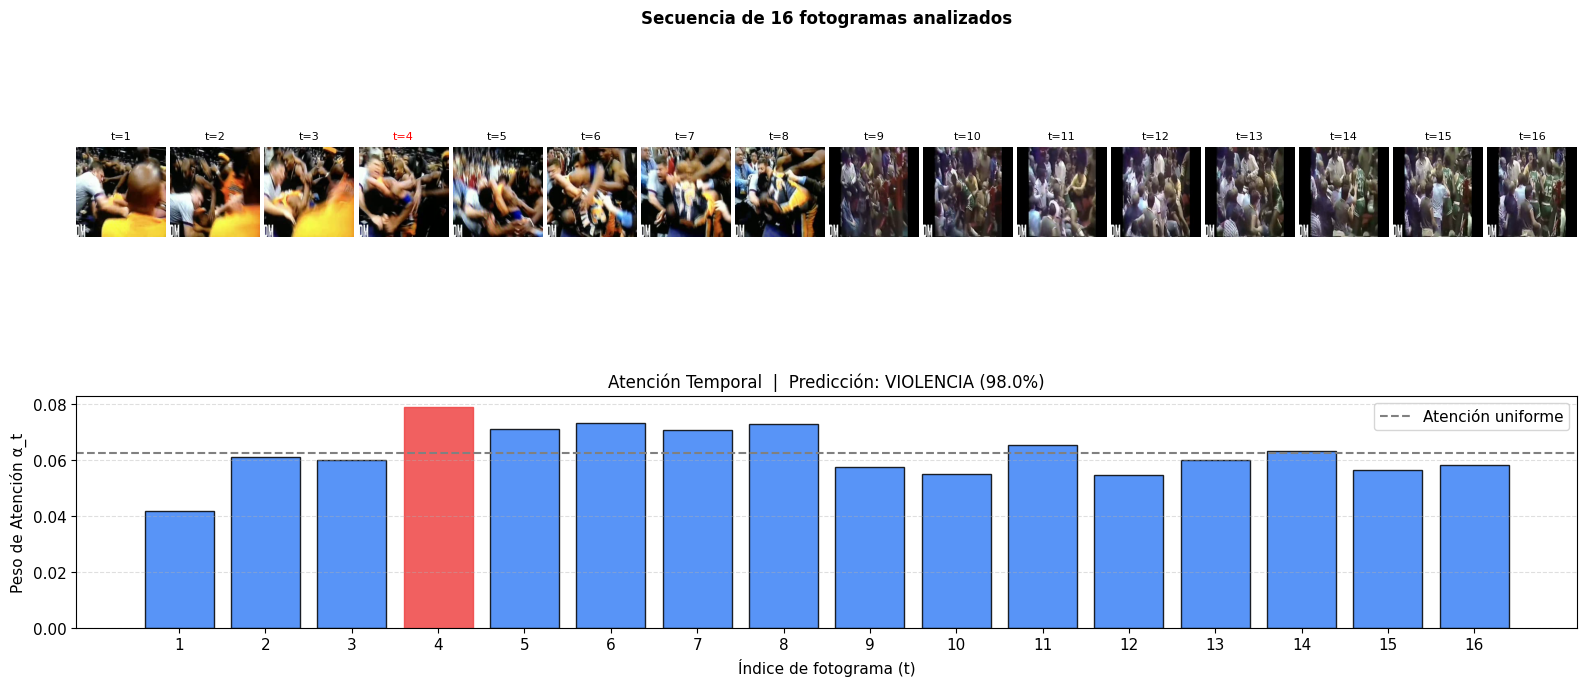

In [ ]:
# ============================================================
# Hacemos una prueba con videos guardados en Pruebas : Violencia No_Violencia
# ============================================================
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

# 1. Subir el video
print("Selecciona el video que quieres analizar...")
uploaded = files.upload()          # se abre el selector de archivos
video_path = list(uploaded.keys())[0]
print(f"\nVideo cargado: {video_path}")

# 2. Cargar el mejor modelo (versión robusta a CCTV)
model = SpatioTemporalViolenceModel(mode="resnet_bilstm_attn").to(DEVICE)
ckpt_path = "checkpoints/best_resnet_bilstm_attn_lima_robust.pt"

if os.path.exists(ckpt_path):
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    print("✓ Modelo robusto cargado correctamente")
else:
    # Si no existe el robusto, usa el propuesto normal
    ckpt_path = "checkpoints/best_resnet_bilstm_attn.pt"
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    print("⚠ Se cargó el modelo sin robustez CCTV (el robusto no se encontró)")

model.eval()

# 3. Extraer los 16 fotogramas
frames_np = extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE)
print(f"Fotogramas extraídos: {frames_np.shape}")

# 4. Convertir a tensor normalizado
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

tensor_frames = torch.from_numpy(frames_np).permute(0, 3, 1, 2).float() / 255.0
tensor_frames = ((tensor_frames - mean) / std).unsqueeze(0).to(DEVICE)  # (1, T, 3, H, W)

# 5. Inferencia
with torch.no_grad():
    logits, attn_weights = model(tensor_frames, return_attention=True)
    prob = torch.sigmoid(logits).item()
    attn_np = attn_weights.squeeze(0).cpu().numpy()

# 6. Resultado
print("\n" + "="*50)
if prob >= 0.5:
    print(f"🚨  ALERTA: VIOLENCIA DETECTADA")
else:
    print(f"✅  NORMAL: SIN VIOLENCIA")
print(f"Probabilidad de violencia: {prob*100:.2f}%")
print(f"Fotograma de máxima atención: t = {np.argmax(attn_np)+1}")
print("="*50)

# 7. Visualización de los 16 fotogramas + curva de atención
fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(2, 1, height_ratios=[1.4, 1.0])

# Fila superior: fotogramas
axes = fig.add_subplot(gs[0])
axes.axis('off')
axes.set_title("Secuencia de 16 fotogramas analizados", fontsize=12, fontweight='bold')

inner = fig.add_gridspec(1, 16, wspace=0.05, top=0.88, bottom=0.55)
for i in range(16):
    ax = fig.add_subplot(inner[0, i])
    ax.imshow(frames_np[i])
    ax.set_title(f"t={i+1}", fontsize=8, color='red' if i == np.argmax(attn_np) else 'black')
    ax.axis('off')

# Fila inferior: pesos de atención
ax_att = fig.add_subplot(gs[1])
bars = ax_att.bar(range(1, 17), attn_np, color="#3b82f6", edgecolor="black", alpha=0.85)
bars[np.argmax(attn_np)].set_color("#ef4444")
ax_att.axhline(1/16, color="gray", linestyle="--", label="Atención uniforme")
ax_att.set_xlabel("Índice de fotograma (t)")
ax_att.set_ylabel("Peso de Atención α_t")
ax_att.set_title(f"Atención Temporal  |  Predicción: {'VIOLENCIA' if prob>=0.5 else 'NO VIOLENCIA'} ({prob*100:.1f}%)")
ax_att.set_xticks(range(1, 17))
ax_att.legend()
ax_att.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

#Puebas 02:
Solo con los modelos corridos más el tipo de violencia.
Bloque 7: Identificar que tipo de caso esta ocurriendo donde existe violencia:

Selecciona el video que quieres analizar desde tu PC...


Saving RLVS_V_568.mp4 to RLVS_V_568 (1).mp4

Video cargado: RLVS_V_568 (1).mp4
✓ Modelo robusto cargado correctamente (best_resnet_bilstm_attn_lima_robust.pt)
Fotogramas extraídos: (16, 224, 224, 3)

🚨  ALERTA: VIOLENCIA DETECTADA
├─ Probabilidad de violencia : 98.00%
├─ Fotograma pico atención   : t = 4 (α_4 = 0.079)
├─ Tipo de violencia (Etapa2): Pelea / Agresión Física (99.5%)
└─ Desglose por categoría    : Pelea: 99.5% | Robo: 0.2% | Violencia con Uso de Armas: 0.1% | Vandalismo: 0.2%
   Elementos detectados      : 1 Persona


/tmp/ipykernel_2762/2963649250.py:174: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


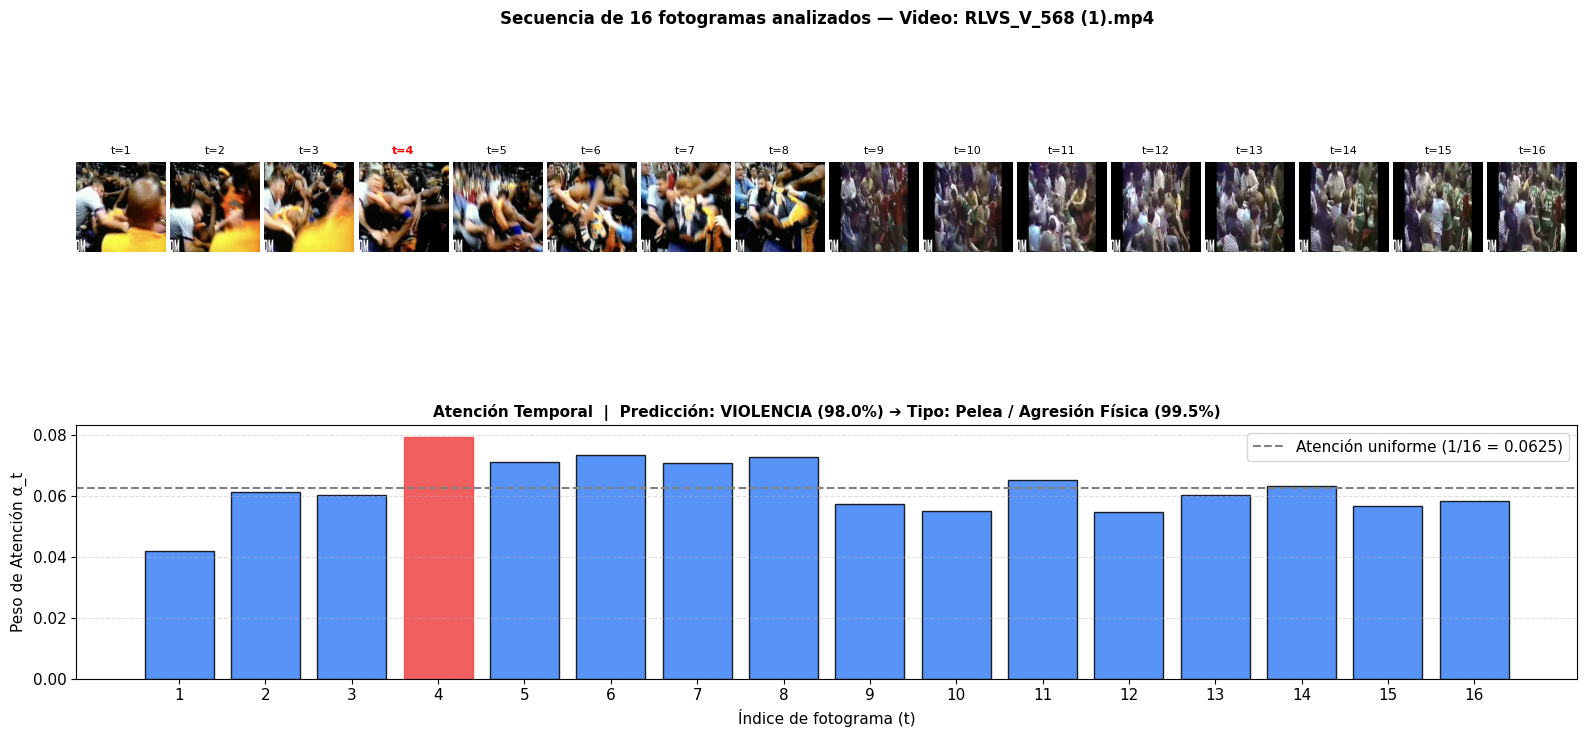

In [ ]:
# ==============================================================================
# INFERENCIA COMPLETA EN UN VIDEO
# Etapa 1: Tu modelo entrenado (best_resnet_bilstm_attn_lima_robust.pt)
# Etapa 2: Tipificación del tipo de violencia (CLIP + YOLOv8) si Prob >= 0.5
# ==============================================================================
from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
import glob
from PIL import Image

# Verificar que los modelos de la Opción 1 (CLIP y YOLO) estén en memoria
if 'clip_model' not in globals() or 'yolo_detector' not in globals():
    !pip install -q transformers ultralytics
    from transformers import CLIPProcessor, CLIPModel
    from ultralytics import YOLO
    clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
    clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    yolo_detector = YOLO("yolov8n.pt")

CATEGORIAS_VIOLENCIA = {
    "Pelea / Agresión Física": "a video frame of people fighting, punching, kicking, or brawling",
    "Robo / Asalto en vía pública": "a surveillance camera frame of a street robbery, mugging, thief stealing or assaulting a victim",
    "Violencia con Uso de Armas": "a person holding a gun, pistol, knife, or weapon threatening or attacking someone",
    "Vandalismo / Disturbios": "people rioting, smashing cars, breaking windows, or street vandalism"
}

OBJETOS_INTERES_COCO = {
    0: "Persona", 1: "Bicicleta", 2: "Auto", 3: "Motocicleta", 24: "Mochila",
    26: "Bolso/Cartera", 28: "Maleta", 34: "Bate/Objeto contundente", 43: "Cuchillo/Arma blanca", 67: "Celular"
}

# ------------------------------------------------------------------------------
# 1. Seleccionar el video (Desde tu PC o desde tu carpeta Pruebas/)
# ------------------------------------------------------------------------------
MODO_ENTRADA = "SUBIR_PC"  # Cambia a "CARPETA_PRUEBAS" si quieres elegir uno de Pruebas/ sin subirlo

if MODO_ENTRADA == "SUBIR_PC":
    print("Selecciona el video que quieres analizar desde tu PC...")
    uploaded = files.upload()
    video_path = list(uploaded.keys())[0]
else:
    lista_pruebas = sorted(glob.glob("Pruebas/Violencia/*.*") + glob.glob("Pruebas/No_Violencia/*.*"))
    for idx, p in enumerate(lista_pruebas):
        print(f"[{idx}] {p}")
    eleccion = int(input("\nIngresa el número del video de 'Pruebas/' que deseas evaluar: "))
    video_path = lista_pruebas[eleccion]

print(f"\nVideo cargado: {video_path}")

# ------------------------------------------------------------------------------
# 2. Cargar tu mejor modelo entrenado (versión robusta a CCTV Lima)
# ------------------------------------------------------------------------------
model = SpatioTemporalViolenceModel(mode="resnet_bilstm_attn").to(DEVICE)
ckpt_path = "checkpoints/best_resnet_bilstm_attn_lima_robust.pt"

if os.path.exists(ckpt_path):
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    print("✓ Modelo robusto cargado correctamente (best_resnet_bilstm_attn_lima_robust.pt)")
else:
    ckpt_path = "checkpoints/best_resnet_bilstm_attn.pt"
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    print("⚠ Se cargó el modelo sin robustez CCTV (best_resnet_bilstm_attn.pt)")

model.eval()

# ------------------------------------------------------------------------------
# 3 y 4. Extraer los 16 fotogramas y convertir a tensor normalizado
# ------------------------------------------------------------------------------
frames_np = extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE)
print(f"Fotogramas extraídos: {frames_np.shape}")

mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

tensor_frames = torch.from_numpy(frames_np).permute(0, 3, 1, 2).float() / 255.0
tensor_frames = ((tensor_frames - mean) / std).unsqueeze(0).to(DEVICE)  # (1, T, 3, H, W)

# ------------------------------------------------------------------------------
# 5. Inferencia Etapa 1 (Detección Espacio-Temporal con tu modelo entrenado)
# ------------------------------------------------------------------------------
with torch.no_grad():
    logits, attn_weights = model(tensor_frames, return_attention=True)
    prob = torch.sigmoid(logits).item()
    attn_np = attn_weights.squeeze(0).cpu().numpy()

top_frame_idx = int(np.argmax(attn_np))
top3_frames_idx = np.argsort(attn_np)[::-1][:3]

# ------------------------------------------------------------------------------
# 6. Inferencia Etapa 2 (Opción 1: ¿Qué tipo de violencia es?) y Reporte
# ------------------------------------------------------------------------------
subtipo_str = "Ninguno (Escena Normal)"
resumen_obj = "-"

print("\n" + "="*65)
if prob >= 0.5:
    # Evaluar los 3 fotogramas de mayor atención temporal con CLIP + YOLOv8
    pil_keyframes = [Image.fromarray(frames_np[i]) for i in top3_frames_idx]
    text_prompts = list(CATEGORIAS_VIOLENCIA.values())
    labels_es = list(CATEGORIAS_VIOLENCIA.keys())

    inputs = clip_processor(text=text_prompts, images=pil_keyframes, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        outputs = clip_model(**inputs)
        probs_por_frame = outputs.logits_per_image.softmax(dim=1).cpu().numpy()
        pesos_top3 = attn_np[top3_frames_idx] / attn_np[top3_frames_idx].sum()
        probs_tipo = np.dot(pesos_top3, probs_por_frame)

    best_idx = int(np.argmax(probs_tipo))
    subtipo_detectado = labels_es[best_idx]
    conf_tipo = probs_tipo[best_idx] * 100.0
    subtipo_str = f"{subtipo_detectado} ({conf_tipo:.1f}%)"

    # Detectar objetos/personas en el fotograma de máxima atención con YOLOv8
    conteo_obj = {}
    yolo_res = yolo_detector(pil_keyframes[0], verbose=False)[0]
    for c_id in yolo_res.boxes.cls.cpu().numpy().astype(int):
        if c_id in OBJETOS_INTERES_COCO:
            nombre_o = OBJETOS_INTERES_COCO[c_id]
            conteo_obj[nombre_o] = conteo_obj.get(nombre_o, 0) + 1
    resumen_obj = ", ".join([f"{v} {k}" for k, v in conteo_obj.items()]) if conteo_obj else "Acción cercana"

    print(f"🚨  ALERTA: VIOLENCIA DETECTADA")
    print(f"├─ Probabilidad de violencia : {prob*100:.2f}%")
    print(f"├─ Fotograma pico atención   : t = {top_frame_idx+1} (α_{top_frame_idx+1} = {attn_np[top_frame_idx]:.3f})")
    print(f"├─ Tipo de violencia (Etapa2): {subtipo_str}")
    print(f"└─ Desglose por categoría    : " + " | ".join([f"{labels_es[k].split('/')[0].strip()}: {probs_tipo[k]*100:.1f}%" for k in range(len(labels_es))]))
    print(f"   Elementos detectados      : {resumen_obj}")
else:
    print(f"✅  NORMAL: SIN VIOLENCIA")
    print(f"├─ Probabilidad de violencia : {prob*100:.2f}%")
    print(f"└─ Fotograma de mayor peso   : t = {top_frame_idx+1} (α_{top_frame_idx+1} = {attn_np[top_frame_idx]:.3f})")
print("="*65)

# ------------------------------------------------------------------------------
# 7. Visualización de los 16 fotogramas + Curva de Atención + Subtipo de Violencia
# ------------------------------------------------------------------------------
fig = plt.figure(figsize=(16, 7.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1.4, 1.0])

# Fila superior: secuencia de 16 fotogramas
axes = fig.add_subplot(gs[0])
axes.axis('off')
axes.set_title(
    f"Secuencia de 16 fotogramas analizados — Video: {os.path.basename(video_path)}",
    fontsize=12, fontweight='bold'
)

inner = fig.add_gridspec(1, 16, wspace=0.05, top=0.88, bottom=0.55)
for i in range(16):
    ax = fig.add_subplot(inner[0, i])
    ax.imshow(frames_np[i])
    es_pico = (i == top_frame_idx)
    ax.set_title(f"t={i+1}", fontsize=8, fontweight='bold' if es_pico else 'normal', color='red' if es_pico else 'black')
    ax.axis('off')

# Fila inferior: pesos de atención temporal
ax_att = fig.add_subplot(gs[1])
bars = ax_att.bar(range(1, 17), attn_np, color="#3b82f6", edgecolor="black", alpha=0.85)
bars[top_frame_idx].set_color("#ef4444")
ax_att.axhline(1/16, color="gray", linestyle="--", label="Atención uniforme (1/16 = 0.0625)")
ax_att.set_xlabel("Índice de fotograma (t)")
ax_att.set_ylabel("Peso de Atención α_t")

estado_titulo = f"VIOLENCIA ({prob*100:.1f}%) ➔ Tipo: {subtipo_str}" if prob >= 0.5 else f"NO VIOLENCIA ({prob*100:.1f}%)"
ax_att.set_title(f"Atención Temporal  |  Predicción: {estado_titulo}", fontsize=11, fontweight='bold')
ax_att.set_xticks(range(1, 17))
ax_att.legend()
ax_att.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(f"results/inferencia_{os.path.splitext(os.path.basename(video_path))[0]}.png", dpi=300, bbox_inches="tight")
plt.show()

# Producto mínimo viable Parte 01:
Ejecución directamente desde Colab para visualizar en una app de forma remota.

In [ ]:
# ==============================================================================
# App Web con GRADIO — EJECUCIÓN DIRECTA DESDE GOOGLE COLAB
# Genera una página web interactiva con URL pública usando la GPU de Colab
# ==============================================================================
!pip install -q gradio transformers ultralytics

import gradio as gr
import torch
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from ultralytics import YOLO

# 1. Asegurar que los modelos de Etapa 1 y Etapa 2 estén cargados en GPU
model_mvp = SpatioTemporalViolenceModel(mode="resnet_bilstm_attn").to(DEVICE)
ckpt_mvp = "checkpoints/best_resnet_bilstm_attn_lima_robust.pt"
if not os.path.exists(ckpt_mvp):
    ckpt_mvp = "checkpoints/best_resnet_bilstm_attn.pt"
model_mvp.load_state_dict(torch.load(ckpt_mvp, map_location=DEVICE))
model_mvp.eval()

if 'clip_model' not in globals():
    clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
    clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
if 'yolo_detector' not in globals():
    yolo_detector = YOLO("yolov8n.pt")

CATEGORIAS_VIOLENCIA = {
    "Pelea / Agresión Física": "a video frame of people fighting, punching, kicking, or brawling",
    "Robo / Asalto en vía pública": "a surveillance camera frame of a street robbery, mugging, thief stealing or assaulting a victim",
    "Violencia con Uso de Armas": "a person holding a gun, pistol, knife, or weapon threatening or attacking someone",
    "Vandalismo / Disturbios": "people rioting, smashing cars, breaking windows, or street vandalism"
}

OBJETOS_INTERES_COCO = {
    0: "Persona", 1: "Bicicleta", 2: "Auto", 3: "Motocicleta", 24: "Mochila",
    26: "Bolso/Cartera", 28: "Maleta", 34: "Bate/Objeto contundente", 43: "Cuchillo/Arma blanca", 67: "Celular"
}

# 2. Función principal que conecta la subida del video en la Web con tus Modelos
def procesar_video_web(video_path):
    if video_path is None:
        return "Por favor sube un video.", {}, None, None

    # Extraer 16 fotogramas
    frames_np = extract_uniform_frames(video_path, seq_len=SEQ_LEN, img_size=IMG_SIZE)
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    tensor_frames = torch.from_numpy(frames_np).permute(0, 3, 1, 2).float() / 255.0
    tensor_frames = ((tensor_frames - mean) / std).unsqueeze(0).to(DEVICE)

    # Etapa 1: Inferencia ResNet50 + Bi-LSTM + Atención Temporal
    with torch.no_grad():
        logits, attn_weights = model_mvp(tensor_frames, return_attention=True)
        prob_violencia = torch.sigmoid(logits).item()
        attn_np = attn_weights.squeeze(0).cpu().numpy()

    top_idx = int(np.argmax(attn_np))
    top3_idx = np.argsort(attn_np)[::-1][:3]
    frame_pico_img = frames_np[top_idx].copy()

    # Etapa 2: Tipificación si Prob >= 0.5
    desglose_categorias = {"Sin Violencia (Normal)": round(1.0 - prob_violencia, 3)}
    if prob_violencia >= 0.5:
        pil_keyframes = [Image.fromarray(frames_np[i]) for i in top3_idx]
        inputs = clip_processor(
            text=list(CATEGORIAS_VIOLENCIA.values()),
            images=pil_keyframes, return_tensors="pt", padding=True
        ).to(DEVICE)
        with torch.no_grad():
            outputs = clip_model(**inputs)
            probs_f = outputs.logits_per_image.softmax(dim=1).cpu().numpy()
            pesos = attn_np[top3_idx] / attn_np[top3_idx].sum()
            probs_tipo = np.dot(pesos, probs_f)

        labels_es = list(CATEGORIAS_VIOLENCIA.keys())
        desglose_categorias = {labels_es[k]: float(probs_tipo[k]) for k in range(len(labels_es))}
        subtipo_ganador = labels_es[int(np.argmax(probs_tipo))]
        conf_ganador = np.max(probs_tipo) * 100

        # Dibujar cajas de YOLOv8 sobre el fotograma pico
        yolo_res = yolo_detector(pil_keyframes[0], verbose=False)[0]
        frame_pico_img = cv2.cvtColor(yolo_res.plot(), cv2.COLOR_BGR2RGB)
        conteo_obj = {}
        for c_id in yolo_res.boxes.cls.cpu().numpy().astype(int):
            if c_id in OBJETOS_INTERES_COCO:
                n_obj = OBJETOS_INTERES_COCO[c_id]
                conteo_obj[n_obj] = conteo_obj.get(n_obj, 0) + 1
        obj_str = ", ".join([f"{v} {k}" for k, v in conteo_obj.items()]) if conteo_obj else "Interacción directa"

        resumen_md = f"""
        ### 🚨 ALERTA ROJA: SITUACIÓN DE VIOLENCIA DETECTADA
        * **Probabilidad Global (ResNet50-BiLSTM-Attn):** `{prob_violencia*100:.2f}%`
        * **Tipificación del Incidente (Etapa 2):** **{subtipo_ganador}** (`{conf_ganador:.1f}%`)
        * **Fotograma Crítico de Máxima Atención:** `Frame t = {top_idx + 1} / 16` ($\alpha_{{{top_idx+1}}} = {attn_np[top_idx]:.3f}$)
        * **Elementos Identificados en Escena:** `{obj_str}`
        """
    else:
        resumen_md = f"""
        ### ✅ ESTADO NORMAL: SIN SITUACIÓN DE VIOLENCIA
        * **Probabilidad de Violencia:** `{prob_violencia*100:.2f}%` (Umbral de alerta: `50.0%`)
        * **Fotograma de Mayor Atención Relativa:** `Frame t = {top_idx + 1} / 16` ($\alpha_{{{top_idx+1}}} = {attn_np[top_idx]:.3f}$)
        * **Diagnóstico:** Actividad cotidiana pacífica.
        """

    # Generar gráfico de la secuencia + curva de atención temporal
    fig = plt.figure(figsize=(14, 6))
    gs = fig.add_gridspec(2, 1, height_ratios=[1.2, 1.0])
    ax_top = fig.add_subplot(gs[0])
    ax_top.axis('off')
    ax_top.set_title("Muestreo Espacio-Temporal (16 Fotogramas) — Rojo indica el Pico de Atención", fontsize=11, fontweight='bold')

    inner = fig.add_gridspec(1, 16, wspace=0.05, top=0.88, bottom=0.55)
    for i in range(16):
        ax = fig.add_subplot(inner[0, i])
        ax.imshow(frames_np[i])
        ax.set_title(f"t={i+1}", fontsize=8, color='red' if i == top_idx else 'black', fontweight='bold' if i == top_idx else 'normal')
        ax.axis('off')

    ax_att = fig.add_subplot(gs[1])
    bars = ax_att.bar(range(1, 17), attn_np, color="#3b82f6", edgecolor="black", alpha=0.85)
    bars[top_idx].set_color("#ef4444")
    ax_att.axhline(1/16, color="gray", linestyle="--", label="Atención uniforme (1/16)")
    ax_att.set_xlabel("Índice de Fotograma (t = 1 ... 16)")
    ax_att.set_ylabel("Peso de Atención α_t")
    ax_att.set_title("Curva de Atención Temporal de la Red Bi-LSTM", fontsize=11, fontweight='bold')
    ax_att.set_xticks(range(1, 17))
    ax_att.legend()
    ax_att.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()

    return resumen_md, desglose_categorias, frame_pico_img, fig

# 3. Construir la Interfaz Web de Gradio
with gr.Blocks(theme=gr.themes.Soft(), title="Sistema de Detección de Violencia - Lima") as demo_web:
    gr.Markdown(
        """
        # 🛡️ Sistema Inteligente de Detección y Tipificación de Violencia Urbana (CCTV Lima)
        **Maestría en Inteligencia Artificial (MIA-203) — Posgrado FIIS UNI**
        *Arquitectura Híbrida: ResNet-50 + Bi-LSTM con Atención Temporal (Etapa 1) + Tipificación Forense CLIP & YOLOv8 (Etapa 2)*
        """
    )
    with gr.Row():
        with gr.Column(scale=1):
            video_input = gr.Video(label="📹 Subir Video de Cámara de Seguridad / Prueba")
            btn_analizar = gr.Button("🔍 Analizar Situación de Violencia", variant="primary")
        with gr.Column(scale=1):
            salida_resumen = gr.Markdown(label="Dictamen del Sistema")
            salida_barras_tipo = gr.Label(num_top_classes=4, label="Probabilidad por Tipo de Incidente")

    with gr.Row():
        with gr.Column(scale=1):
            salida_frame_pico = gr.Image(label="🎯 Fotograma Pico de Atención + Detección YOLOv8")
        with gr.Column(scale=2):
            salida_grafico = gr.Plot(label="📈 Análisis Espacio-Temporal (16 Frames y Pesos α_t)")

    btn_analizar.click(
        fn=procesar_video_web,
        inputs=video_input,
        outputs=[salida_resumen, salida_barras_tipo, salida_frame_pico, salida_grafico]
    )

# Lanzar con enlace público (share=True) para abrirlo desde cualquier navegador en tu PC
demo_web.launch(share=True, debug=False)

/tmp/ipykernel_2762/341382668.py:138: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Sistema de Detección de Violencia - Lima") as demo_web:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dea449128ee2c874d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Producto mínimo viable Parte 02:
Visualizar en una app de forma local .

In [ ]:
from google.colab import files
files.download("checkpoints/best_resnet_bilstm_attn_lima_robust.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bloque 7: Generación Automática del Repositorio Reproducible para GitHub (Criterios 3 y 5)
La siguiente celda empaqueta automáticamente todos los scripts modulares (`src/`), configuraciones (`configs/`), tablas de resultados (`results/`), archivo `requirements.txt` y el `README.md` con las instrucciones exactas para regenerar cada tabla y figura del artículo IEEE.

In [ ]:
REPO_NAME = "violencia-lima-dl"
os.makedirs(f"{REPO_NAME}/src", exist_ok=True)
os.makedirs(f"{REPO_NAME}/configs", exist_ok=True)
os.makedirs(f"{REPO_NAME}/results", exist_ok=True)
os.makedirs(f"{REPO_NAME}/notebooks", exist_ok=True)
os.makedirs(f"{REPO_NAME}/data", exist_ok=True)

# Copiar tablas y figuras generadas a la carpeta results/ del repositorio
for f_res in glob.glob("results/*"):
    shutil.copy(f_res, f"{REPO_NAME}/results/")

# Crear archivo de configuración YAML
with open(f"{REPO_NAME}/configs/resnet_bilstm_att.yaml", "w") as f:
    f.write("""seed: 42
dataset: mohamedmustafa/real-life-violence-situations-dataset
seq_len: 16
img_size: 224
batch_size: 16
epochs: 8
learning_rate: 0.0003
weight_decay: 0.0001
backbone: resnet50_imagenet1k_v2
embed_dim: 512
hidden_dim: 256
dropout: 0.3
label_smoothing: 0.05
""")

# Crear requirements.txt con versiones exactas
with open(f"{REPO_NAME}/requirements.txt", "w") as f:
    f.write("""torch>=2.1.0
torchvision>=0.16.0
kagglehub>=0.2.0
opencv-python-headless>=4.8.0
scikit-learn>=1.3.0
grad-cam>=1.5.0
pandas>=2.0.0
numpy>=1.24.0
matplotlib>=3.7.0
seaborn>=0.12.2
tqdm>=4.65.0
PyYAML>=6.0
""")

# Crear README.md siguiendo las normas del Examen Final MIA-203
with open(f"{REPO_NAME}/README.md", "w") as f:
    f.write("""# Detección Espacio-Temporal de Violencia Urbana mediante Redes ResNet-BiLSTM con Atención y Transferencia de Dominio a Videovigilancia en Lima

Proyecto Integrador Final — **MIA-203 Redes Neuronales y Aprendizaje Profundo** (Posgrado FIIS - UNI).

## Integrantes del Equipo
* **Alvaro Alejandro Siesquén Abad**
* **Kiara Isumi Alvarez Barrionuevo**
* **Sergio Alonso Ortiz Pauca**
* **Alfonso Pérez Ramos**

## Cómo Reproducir los Resultados
1. Instalar dependencias:
   ```bash
   pip install -r requirements.txt
   ```
2. Ejecutar de principio a fin el cuaderno principal en Google Colab (GPU T4):
   `notebooks/Proyecto_violencia_Lima.ipynb`
3. Todas las tablas y figuras del artículo IEEE se exportan automáticamente en `results/`.
""")

print(f"Estructura completa del repositorio generada en: {os.path.abspath(REPO_NAME)}")
!ls -lh {REPO_NAME} {REPO_NAME}/results